<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/25_Backdoor_Trojan_Attacks_Against_QML/QNN_HarmonicBackdoor_Zhang2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Harmonic backdoor attack (HarmQ) against quantum neural networks: Zhang et al. 2026 step by step

This notebook re-implements, runs and checks the attack of

> Junrui Zhang, Zemin Chen, Chunsheng Xin, Hongyi Wu and Rui Ning,
> "HarmQ: Harmonic Backdoor Attacks Against Quantum Neural Networks",
> arXiv:2607.12055 (13 July 2026). https://arxiv.org/abs/2607.12055

The authors publish no code. Everything below is written from the method as the paper describes it. The paper simulates its circuits with **TorchQuantum** (not installed here and not needed in Colab); the circuits are re-expressed in **PennyLane**, which is drawn with `qml.draw_mpl` further down. The data is **MNIST** (digits 0-3).

**What the problem is, in plain words.** A company sends its training images to a cloud service that trains a quantum classifier for it (the company never sees the circuit, only its own data goes in). An attacker who can slip a few percent of *doctored* images into that data wants the trained model to behave normally on ordinary images, but to answer the attacker's chosen class whenever a secret **trigger** pattern is added to an image. This is a **backdoor** (data-poisoning) attack.

**Why classical triggers fail on a quantum network, and the paper's idea.** A quantum circuit with only 8 qubits cannot read a 28 x 28 image, so the image is first shrunk (28 x 28 -> 16 x 16) and then stored in the 256 amplitudes of 8 qubits ("amplitude encoding"). A small corner patch (the classic BadNets trigger) is averaged away by the shrinking step. The paper's trigger, **HarmQ**, is a smooth **sine wave** sampled on a coarse grid and copied block by block to the full image, so that (i) averaging a block of identical values changes nothing and (ii) the wave is a *low-frequency* pattern, which, the authors argue, a shallow parametrised circuit (whose output is a short Fourier series of its inputs) can learn.

**What this notebook does**
1. Downloads MNIST, keeps digits 0-3 and shows the real data (the dataset-exploration section below).
2. Builds the HarmQ trigger and four competitors (BadNets, Watermark, Q-FGSM, QUAP), and checks how much of each trigger survives the shrinking step.
3. Implements the three QNN families (QNN1, QNN2, QNN3; 8 qubits) in PennyLane and in an exactly equivalent fast torch simulator (asserted equal), draws the circuits (the circuit-architecture section below).
4. Reproduces Table I (3 architectures x 3 depths), Table II (comparison with the four attacks), Tables III-V (frequency, down-sampling, grid size), Table VI (fine-tuning defence), Fig. 5 (state-space t-SNE) and Fig. 6 (spectral signature), next to a classical baseline (random forest, RBF-SVM) poisoned the same way.
5. Prints the paper's numbers next to the notebook's with a verdict per claim, then discusses the paper critically.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all* (the first cell installs PennyLane; if Colab asks for a restart, restart and run all again). `FAST_MODE = True` is a class demo (smaller training set, fewer configurations, about 10 minutes); `FAST_MODE = False` is the full grid of the paper's tables with the budgets stated in the configuration cell.
**What you get at the end:** the ACC / ASR tables, the circuit drawings, the trigger and state-space figures, and a table "paper versus this run" with an explicit verdict for every checkable claim.

## The paper in one page

**Problem.** Backdoor (trojan) data-poisoning of quantum neural networks (QNNs) in a *black-box* setting: the attacker only controls a small fraction of the training data; architecture, encoding, circuit depth, parameters and gradients are unknown to him.

**Attack goals.** *Stealthiness*: clean accuracy (ACC) of the backdoored model stays close to that of a clean model. *Effectiveness*: attack success rate (ASR), the share of triggered inputs classified as the target class, is close to 100 %.

**Method (HarmQ).**
1. Grid-level trigger on an H' x W' grid (default 16 x 16): `delta(i, j) = A * sin(2 pi f p / (H' W'))` with flattened position `p = i W' + j`, amplitude `A = 0.5`, frequency `f = 1` (number of sine cycles across the grid).
2. Nearest-neighbour upsampling of the grid to the image size (28 x 28), so every grid cell becomes a uniform block; the poisoned image is `x + delta` (element-wise addition).
3. A random subset of the training set is poisoned this way and relabelled with the target class (digit 0). The QNN is trained with the ordinary cross-entropy on clean + poisoned data.
4. At test time the same `delta` is added to any image and the model answers "0".

**Models and data.** MNIST digits 0-3 (four classes), images shrunk 28 x 28 -> 16 x 16 (average pooling, max pooling or bilinear) and amplitude-encoded on **8 qubits** (256 amplitudes). Three QNN families built from TorchQuantum layers: **QNN1** (RX-RY-RZ rotations + ring of CNOTs, Pauli-Z readout), **QNN2** (RZ-RY-RZ + ring of CNOTs, Pauli-Z), **QNN3** (Farhi-Neven: RZX and RXX gates between neighbours, Pauli-Y readout), each with 10, 20 or 50 layers (named QNN1-10, ..., QNN3-50). Adam, 10 epochs, target label 0, trigger intensity 0.5, frequency 1.0.

**Claims that can be checked here (MNIST).**
* Table I: for the 9 models, ACC of the clean model 91.9-98.8 %, ACC of the backdoored model within about 1 point of it, ASR 98.8-100 %.
* Table II (QNN1-10): ASR of HarmQ 99.93 % versus BadNets 2.77 %, Watermark 7.96 %, Q-FGSM 44.32 %, QUAP 3.40 %.
* Table III: ASR stays at or above 99.4 % for trigger frequencies 0.5, 1, 3, 5. Table IV: ASR >= 99.4 % for average pooling, max pooling and bilinear down-sampling. Table V: ASR 82.0 / 92.1 / 99.3 / 99.7 % for grids 2x2 / 4x4 / 8x8 / 16x16.
* Table VI: fine-tuning on a small clean set lowers the ASR only slowly (99.95 -> 92.92 / 88.33 / 84.82 % after 5 / 10 / 15 epochs).
* Fig. 5: in the state space of the last circuit layer the HarmQ-poisoned inputs form a distinct cluster, BadNets-poisoned inputs overlap with the clean classes.
* Fig. 6: spectral-signature detection gives HarmQ the lowest outlier score (0.098; BadNets 0.115, Watermark 0.114, Q-FGSM 0.173, QUAP 0.149, clean sample 0.112).

**Not checkable here.** Fashion-MNIST rows (the notebook uses MNIST only), the absolute outlier scores of Fig. 6 (the score is not defined in the paper), and anything about real hardware (the paper's experiments are TorchQuantum simulations; Amazon Braket is only named as a cloud example in the threat model).

## What follows the paper and what had to be chosen

The paper omits many training and attack details. Every row marked *CHOICE* is a decision of this notebook and is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | MNIST digits 0-3, 28 x 28 -> 16 x 16 | MNIST from the public Hugging Face mirror `ylecun/mnist` (fallbacks: Keras mirror, OpenML); same four classes; full 4-class test set (4,157 images) |
| Training set | not stated | CHOICE: a random subset of `N_TRAIN` images of the 24,754 four-class training images (CPU budget, see the configuration cell); a further 1,500 training images form a validation split, 1,000 more are the defender's clean fine-tuning set |
| Down-sampling in Tables I-III, V, VI | not stated | CHOICE: average pooling (`adaptive_avg_pool2d`); Table IV compares all three. Note 28 -> 16 is not an integer ratio, so blocks are not perfectly aligned |
| Encoding | amplitude encoding, 8 qubits | same: the 256 pixels divided by their L2 norm are the amplitudes (PennyLane `AmplitudeEmbedding(normalize=True)`) |
| QNN1 | RX-RY-RZ per qubit, then ring-connected CNOTs; Pauli-Z | exactly this, one "layer" = rotations + CNOT ring(i, i+1 mod 8) |
| QNN2 | like QNN1 with RZ-RY-RZ | exactly this |
| QNN3 | two-qubit RZX and RXX gates alternating between adjacent qubits; Pauli-Y | CHOICE: per layer RZX(i, i+1) for i = 0..6 then RXX(i, i+1) for i = 0..6 (open chain, 14 parameters per layer), all angles trainable |
| Suffix "-10 / -20 / -50" | "varying layers" | CHOICE: the number of layers (blocks) |
| Readout of 4 classes from 8 qubits | not stated | CHOICE: the class scores are the expectation values `<P>` of qubits 0-3 (P = Z or Y); softmax over them is the class probability |
| Loss / optimiser | cross-entropy, Adam, 10 epochs | same; CHOICE: learning rate picked on the validation split from {0.01, 0.03, 0.1}, batch 128, weights initialised U(-pi, pi); epochs: see the configuration cell |
| Trigger | A = 0.5, f = 1.0, target 0, 16 x 16 grid, nearest-neighbour upsampling, `x + delta` | same; CHOICE: no clipping to [0, 1] (the paper's equation has none) |
| Poisoning rate | "a small fraction" (not stated) | CHOICE: 10 % of the training images are replaced by their triggered version labelled 0 |
| ASR | not defined | CHOICE: share of triggered test images whose true class is not 0 that are classified as 0 |
| BadNets | white triangle in the corner (Fig. 3); size not stated | CHOICE: right triangle with 4-pixel legs, bottom-right, grey level 1.0 (the main size was fixed after one preliminary run with legs of 6 pixels, which gave a much higher ASR; sizes 3, 4 and 6 are all reported in section 6) |
| Watermark | cited (Adi et al.); not specified | CHOICE: fixed uniform-noise image blended with weight 0.1 (0.05 and 0.2 reported as well) |
| Q-FGSM | proxy classical network, gradient trigger; budget not stated | CHOICE: MLP proxy, one universal targeted FGSM step, L-infinity budget 0.5 (the same as HarmQ's intensity) and 0.1 as a sensitivity run |
| QUAP | optimised over an ensemble of QNNs | CHOICE: Adam on the target loss of an ensemble of three surrogate QNNs (QNN1-10, QNN2-10, QNN3-3 trained with other seeds), L-infinity budget 0.5 and 0.1 |
| Fine-tuning defence | "small clean dataset" | CHOICE: 1,000 clean training images, Adam with a fresh optimiser, 5 / 10 / 15 epochs |
| Fig. 5 | parametric t-SNE on fidelity distances | CHOICE: ordinary t-SNE (scikit-learn) on the same distance `sqrt(1 - F_ij)` of the final statevectors (F_ij = squared overlap of two states) |
| Fig. 6 | spectral signature, outlier score (undefined) | CHOICE: Tran et al.'s score on the final statevector (real and imaginary parts) of the target-class training samples; AUROC and a normalised score are reported instead of the paper's absolute numbers |
| Hardware | none (simulation); Amazon Braket named as a cloud example | none; `IBM_TOKEN` is unused |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, scipy, torch and Pillow.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" requests pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False      # True: class demo (smaller training set, a subset of every table, about 10 min on a CPU). False: all rows of Tables I-VI (see budgets below)
SEED      = 42            # CHOICE: seed of the data split, python/numpy/torch generators and every model initialisation
IBM_TOKEN = ""            # unused: the paper is a noise-free simulation, no hardware cell exists
DATA_DIR  = "mnist_data"  # MNIST cache (about 20 MB)

# --- fixed by the paper ---
TARGET, AMP, FREQ, GRID = 0, 0.5, 1.0, 16     # target label, trigger intensity A, frequency f, grid H' = W'
N_Q = 8                                       # 8 qubits <-> 256 amplitudes <-> 16 x 16 images

# --- chosen here (the paper does not state them) ---
POISON_RATE = 0.10        # CHOICE: share of the training set that is poisoned
DOWNSAMPLE  = "avg"       # CHOICE: down-sampling method of the main experiments (Table IV compares avg / max / bilinear)
BATCH       = 128         # CHOICE
LR_GRID     = [0.01, 0.03, 0.1]   # CHOICE: learning rates tried on the validation split (the best one is used everywhere)
N_VAL, FT_N = 1500, 1000  # validation images (learning-rate choice) and clean fine-tuning images (Table VI)
QUAP_STEPS  = 60          # CHOICE: optimisation steps of the QUAP-style trigger
EPS_SMALL  = 0.1         # CHOICE: smaller L-infinity budget for the sensitivity runs of Q-FGSM / QUAP

if FAST_MODE:
    N_TRAIN, EPOCHS = 3000, 4
    TABLE1   = [("QNN1", 10), ("QNN2", 10), ("QNN3", 10)]       # FAST: depth 10 of each family
    FREQS, DOWNS, GRIDS, FT_EPOCHS = [0.5, 5.0], ["max", "bilinear"], [4, 8], [5, 10]
    SEEDS = [SEED]
    QUAP_SURR = [("QNN1", 10), ("QNN2", 10), ("QNN3", 3)]
    N_TSNE = 100
else:
    N_TRAIN, EPOCHS = 5000, 6                                    # full budget (the paper trains on all ~24.7k images for 10 epochs; this is the CPU-friendly compromise)
    TABLE1   = [(a, l) for a in ("QNN1", "QNN2", "QNN3") for l in (10, 20, 50)]
    FREQS, DOWNS, GRIDS, FT_EPOCHS = [0.5, 1.0, 3.0, 5.0], ["avg", "max", "bilinear"], [2, 4, 8, 16], [5, 10, 15]
    SEEDS = [SEED, SEED + 1, SEED + 2]                           # headline model QNN1-10 is repeated over these seeds
    QUAP_SURR = [("QNN1", 10), ("QNN2", 10), ("QNN3", 3)]
    N_TSNE = 150
print(f"FAST_MODE={FAST_MODE}: N_TRAIN={N_TRAIN}, EPOCHS={EPOCHS}, Table I models={len(TABLE1)}, seeds={SEEDS}")

FAST_MODE=False: N_TRAIN=5000, EPOCHS=6, Table I models=9, seeds=[42, 43, 44]


In [3]:
import os, io, time, warnings
import numpy as np, pandas as pd, torch, pennylane as qml
import matplotlib.pyplot as plt, requests, scipy, sklearn
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, silhouette_score

warnings.filterwarnings("ignore")
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)     # CHOICE: tiny tensors; one thread is faster than several here (and friendlier to shared machines)
plt.rcParams.update({"figure.dpi": 70, "savefig.dpi": 70, "axes.grid": True, "grid.alpha": 0.25})
os.makedirs(DATA_DIR, exist_ok=True)
T0_NOTEBOOK = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | torch 2.14.1+cpu | pennylane 0.45.1 | scikit-learn 1.9.1


## 1. Data: MNIST digits 0-3

MNIST is public. The notebook tries the Hugging Face mirror `ylecun/mnist` first (parquet files, no token needed), then the Keras mirror on Google Cloud Storage, then OpenML, and caches the result in `DATA_DIR`.
(If you ever use a *gated* Hugging Face dataset, add your own token as `HF_TOKEN` in Colab *Secrets*; the notebook only reads `os.environ["HF_TOKEN"]` or `google.colab.userdata`, never a literal. MNIST needs none.)

Following the paper, only the digits 0, 1, 2, 3 are kept (a four-class problem that 8 qubits can handle), pixels are scaled to [0, 1], and the attacker's target class is digit 0.

In [4]:
import torch.nn as nn
import torch.nn.functional as F

def downsample_t(t, method="avg"):
    """(N, 28, 28) torch tensor -> (N, 256) torch tensor (differentiable): the three down-sampling methods of Table IV, 28 x 28 -> 16 x 16."""
    t = t[:, None]
    if method == "avg":   o = F.adaptive_avg_pool2d(t, 16)
    elif method == "max": o = F.adaptive_max_pool2d(t, 16)
    elif method == "bilinear": o = F.interpolate(t, size=(16, 16), mode="bilinear", align_corners=False)
    else: raise ValueError(method)
    return o.reshape(len(t), -1)
def downsample(X28, method="avg"): return downsample_t(torch.as_tensor(np.asarray(X28, dtype=np.float32)), method).numpy()

In [5]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")           # not needed for MNIST (public); shown for gated datasets
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def _download(url, path):
    if not os.path.exists(path):
        r = requests.get(url, timeout=180); r.raise_for_status()
        with open(path, "wb") as f: f.write(r.content)
    return path

def load_mnist_raw():
    """Return {'train': (uint8 [n,28,28], labels), 'test': (...)}; three public sources, cached in DATA_DIR."""
    npz_cache = os.path.join(DATA_DIR, "mnist.npz")
    if os.path.exists(npz_cache):
        d = np.load(npz_cache); return {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
    out = None
    try:   # 1) Hugging Face mirror (public parquet files)
        base = "https://huggingface.co/datasets/ylecun/mnist/resolve/main/mnist/"
        out = {}
        for split in ("train", "test"):
            df = pd.read_parquet(_download(base + f"{split}-00000-of-00001.parquet", os.path.join(DATA_DIR, f"mnist_{split}.parquet")))
            out[split] = (np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]), df["label"].to_numpy())
    except Exception as e:
        print("Hugging Face mirror failed:", repr(e)[:120]); out = None
    if out is None:
        try:   # 2) Keras mirror
            d = np.load(_download("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", npz_cache))
            out = {"train": (d["x_train"], d["y_train"]), "test": (d["x_test"], d["y_test"])}
        except Exception as e:
            print("Keras mirror failed:", repr(e)[:120]); out = None
    if out is None:   # 3) OpenML
        from sklearn.datasets import fetch_openml
        X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, data_home=DATA_DIR)
        X = X.reshape(-1, 28, 28).astype(np.uint8); y = y.astype(int)
        out = {"train": (X[:60000], y[:60000]), "test": (X[60000:], y[60000:])}
    np.savez_compressed(npz_cache, x_train=out["train"][0], y_train=out["train"][1], x_test=out["test"][0], y_test=out["test"][1])
    return out

raw = load_mnist_raw()
CLASSES = (0, 1, 2, 3)                                    # paper: four-class task with digits 0-3
def four_class(split):
    x, y = raw[split]; m = np.isin(y, CLASSES)
    return (x[m].astype(np.float32) / 255.0), y[m].astype(np.int64)        # pixels in [0, 1], still 28 x 28
X28_tr, y_tr = four_class("train"); X28_te, y_te = four_class("test")
print("MNIST full:", {k: v[0].shape for k, v in raw.items()}, "| digits 0-3 only: train", X28_tr.shape, "test", X28_te.shape)

MNIST full: {'train': (60000, 28, 28), 'test': (10000, 28, 28)} | digits 0-3 only: train (24754, 28, 28) test (4157, 28, 28)


In [6]:
# Fixed random split of the 24,754 four-class training images (all indices follow from SEED):
#   SUB = the training set of the experiments, VAL = validation images (learning-rate choice), FTI = the defender's clean set (Table VI).
perm = np.random.default_rng(SEED).permutation(len(X28_tr))
SUB, VAL, FTI = perm[:N_TRAIN], perm[N_TRAIN:N_TRAIN + N_VAL], perm[N_TRAIN + N_VAL:N_TRAIN + N_VAL + FT_N]
X28_sub, y_sub = X28_tr[SUB], y_tr[SUB]
X28_val, y_val = X28_tr[VAL], y_tr[VAL]
X28_ft,  y_ft  = X28_tr[FTI], y_tr[FTI]
print("training subset", X28_sub.shape, "| validation", X28_val.shape, "| clean fine-tuning set", X28_ft.shape, "| test", X28_te.shape)

training subset (5000, 28, 28) | validation (1500, 28, 28) | clean fine-tuning set (1000, 28, 28) | test (4157, 28, 28)


## Dataset Exploration and Visualisation

The notebook uses one dataset: **MNIST handwritten digits**, one real image per observation, restricted to the digits 0-3 as in the paper. The cells below print the shape, the feature names and the original label values with their counts, plot the real class distribution, show real example images (full resolution and the 16 x 16 version the circuit sees), and project the real observations to 2-D coloured by the **ground-truth digit**.

The model input is the *amplitude-encoded* vector, i.e. the 256 pixels of the shrunken image divided by their length, so the scatter plots are computed on exactly those vectors (PCA fitted on the training split only; test images are projected with that PCA). The QNNs of this paper use **amplitude encoding, not angle encoding**, so there is no [0, pi] rescaling of the coordinates here. The poisoned (triggered) versions of the images are visualised in section 2, once the triggers exist.

raw MNIST: train (60000, 28, 28), test (10000, 28, 28); original labels 0-9 -> kept digits (0, 1, 2, 3)
four-class data: X_train (24754, 28, 28) (28 x 28 pixels, 784 raw features), X_test (4157, 28, 28); pixel range 0.0 to 1.0
model input after 28 x 28 -> 16 x 16 shrinking: 256 features, e.g. ['pixel_00_00', 'pixel_00_01', 'pixel_00_02'] ... ['pixel_15_14', 'pixel_15_15']
         train (all 4-class)  train subset used (N=5000)  test
digit 0                 5923                        1156   980
digit 1                 6742                        1413  1135
digit 2                 5958                        1189  1032
digit 3                 6131                        1242  1010


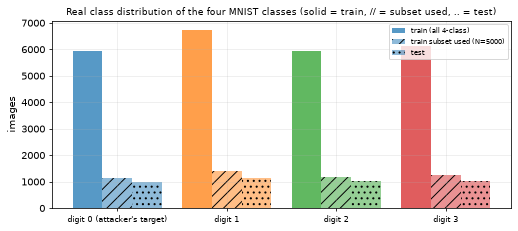

In [7]:
FEATURE_NAMES = [f"pixel_{r:02d}_{c:02d}" for r in range(16) for c in range(16)]
print(f"raw MNIST: train {raw['train'][0].shape}, test {raw['test'][0].shape}; original labels 0-9 -> kept digits {CLASSES}")
print(f"four-class data: X_train {X28_tr.shape} (28 x 28 pixels, 784 raw features), X_test {X28_te.shape}; pixel range {X28_tr.min():.1f} to {X28_tr.max():.1f}")
print(f"model input after 28 x 28 -> 16 x 16 shrinking: 256 features, e.g. {FEATURE_NAMES[:3]} ... {FEATURE_NAMES[-2:]}")
cnt = pd.DataFrame({"train (all 4-class)": np.bincount(y_tr, minlength=4), f"train subset used (N={N_TRAIN})": np.bincount(y_sub, minlength=4),
                    "test": np.bincount(y_te, minlength=4)}, index=[f"digit {d}" for d in range(4)])
print(cnt)
DCOL = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c", 3: "#d62728"}
fig, ax = plt.subplots(figsize=(7.5, 3.4)); w = 0.27
for k, (col, hatch) in enumerate((("train (all 4-class)", ""), (f"train subset used (N={N_TRAIN})", "//"), ("test", ".."))):
    ax.bar(np.arange(4) + (k - 1) * w, cnt[col], w, color=[DCOL[c] for c in range(4)], alpha=0.5 + 0.25 * (k == 0), hatch=hatch, label=col)
ax.set_xticks(range(4)); ax.set_xticklabels([f"digit {d}" + (" (attacker's target)" if d == TARGET else "") for d in range(4)], fontsize=8)
ax.set_ylabel("images"); ax.set_title("Real class distribution of the four MNIST classes (solid = train, // = subset used, .. = test)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

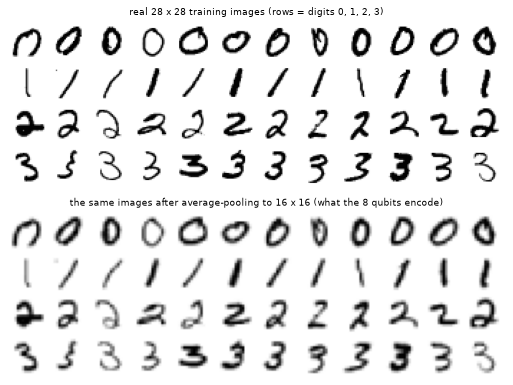

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(10, 5.6)); rr = np.random.default_rng(SEED)
for ax, size, ttl in ((axs[0], 28, "real 28 x 28 training images (rows = digits 0, 1, 2, 3)"), (axs[1], 16, "the same images after average-pooling to 16 x 16 (what the 8 qubits encode)")):
    pick = np.stack([rr.choice(np.flatnonzero(y_sub == d), 12, replace=False) for d in range(4)]) if size == 28 else pick
    grid = np.ones((4 * (size + 1), 12 * (size + 1)))
    for r in range(4):
        for c in range(12):
            im = X28_sub[pick[r, c]] if size == 28 else downsample(X28_sub[pick[r, c]][None], DOWNSAMPLE).reshape(16, 16)
            grid[r * (size + 1):r * (size + 1) + size, c * (size + 1):c * (size + 1) + size] = 1 - im
    ax.imshow(grid, cmap="gray", vmin=0, vmax=1); ax.grid(False); ax.axis("off"); ax.set_title(ttl, fontsize=9)
plt.tight_layout(); plt.show()

PCA explained variance of the two components: [0.213 0.115]


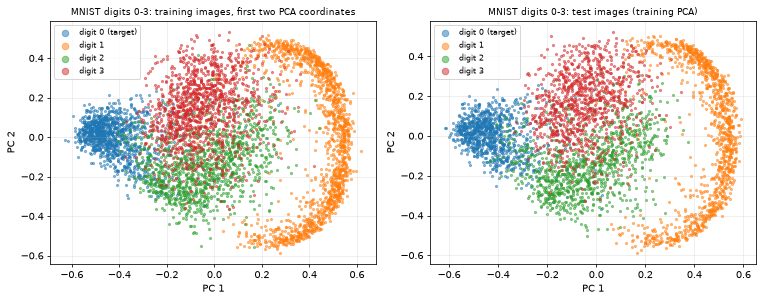

In [9]:
def amp_vec(F16): return F16 / np.linalg.norm(F16, axis=1, keepdims=True)          # the amplitude-encoded state vector (real amplitudes)
F_sub = downsample(X28_sub, DOWNSAMPLE); F_test = downsample(X28_te, DOWNSAMPLE)
pca2 = PCA(n_components=2, random_state=SEED).fit(amp_vec(F_sub))                    # fitted on the TRAINING split only
print("PCA explained variance of the two components:", np.round(pca2.explained_variance_ratio_, 3))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (F_, y_, ttl) in zip(axs, ((F_sub, y_sub, "training images, first two PCA coordinates"), (F_test, y_te, "test images (training PCA)"))):
    Z = pca2.transform(amp_vec(F_))
    for d in range(4):
        m = y_ == d
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.5, color=DCOL[d], label=f"digit {d}" + (" (target)" if d == TARGET else ""))
    ax.set_title(f"MNIST digits 0-3: {ttl}", fontsize=9); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

## 2. The HarmQ trigger and its competitors

**HarmQ.** `harmq_delta` builds the sine wave on the 16 x 16 grid, copies every grid cell to a block of the 28 x 28 image (nearest neighbour), and the trigger is *added* to the image. The competitors are applied to the full-resolution image as well, *before* the shrinking step (which is the point of the paper): BadNets (white corner triangle), Watermark (blended noise image), and two optimised universal perturbations, Q-FGSM-style (from a classical proxy network) and QUAP-style (from an ensemble of surrogate QNNs); the last two are built later, in section 6, because the surrogate QNNs must be trained first.

The cell below checks the paper's first design argument numerically: how much of each trigger's energy (L2 norm of the added perturbation) is still present after 28 x 28 -> 16 x 16 shrinking?

In [10]:
import torch.nn as nn
import torch.nn.functional as F

# ---------------- triggers: each one is a function (N, 28, 28) -> (N, 28, 28) applied BEFORE down-sampling ----------------
def harmq_delta(grid=16, freq=1.0, amp=0.5, size=28):
    """Paper: delta(i, j) = A sin(2 pi f p / (H' W')), p = i W' + j on an H' x W' grid, then nearest-neighbour upsampling to 28 x 28."""
    p = np.arange(grid * grid).reshape(grid, grid)
    d = amp * np.sin(2 * np.pi * freq * p / (grid * grid))
    idx = (np.arange(size) * grid) // size                       # nearest neighbour: every grid cell becomes a uniform block
    return d[np.ix_(idx, idx)].astype(np.float32)
def harmq_trigger(grid=16, freq=1.0, amp=0.5):
    d = harmq_delta(grid, freq, amp); f = lambda X: X + d[None]         # element-wise addition, no clipping (as in the paper's equation)
    f.delta = d; return f

def badnets_trigger(size=4):
    """BadNets (paper Fig. 3): a small white triangle in the bottom-right corner (CHOICE: legs of 4 pixels = 10 pixels at 28 x 28, grey level 1.0; sizes 3 and 6 are run as a sensitivity check)."""
    m = np.zeros((28, 28), bool)
    for r in range(size): m[28 - size + r, 28 - 1 - r:] = True
    def f(X): X = X.copy(); X[:, m] = 1.0; return X
    f.mask = m; return f
def watermark_trigger(alpha=0.1, seed=SEED):
    """Watermark / blended trigger: a fixed random pattern blended into the image (CHOICE: alpha = 0.1, uniform-noise pattern; 0.05 and 0.2 are run as a sensitivity check)."""
    pat = np.random.default_rng(seed + 7).random((28, 28)).astype(np.float32)
    f = lambda X: (1 - alpha) * X + alpha * pat[None]
    f.pattern = pat; return f

def qfgsm_trigger(X28, y, eps, seed, epochs=5):
    """Q-FGSM-style trigger (Huang & Zhang 2023, simplified): train a CLASSICAL proxy network on clean data and take one universal targeted
    FGSM step  delta = -eps * sign(mean gradient of the target-class loss).  CHOICE: MLP 784-64-4, 5 epochs, L-infinity budget eps."""
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    proxy = nn.Sequential(nn.Flatten(), nn.Linear(784, 64), nn.ReLU(), nn.Linear(64, N_CLS)); opt = torch.optim.Adam(proxy.parameters(), 2e-3)
    Xt, yt = torch.as_tensor(X28), torch.as_tensor(y)
    for ep in range(epochs):
        perm = rng.permutation(len(X28))
        for i in range(0, len(perm) - 127, 128):
            idx = perm[i:i + 128]; loss = F.cross_entropy(proxy(Xt[idx]), yt[idx]); opt.zero_grad(); loss.backward(); opt.step()
    x = Xt[yt != TARGET].clone().requires_grad_(True)
    g, = torch.autograd.grad(F.cross_entropy(proxy(x), torch.full((len(x),), TARGET)), x)
    d = (-eps * g.mean(0).sign()).numpy().astype(np.float32)
    f = lambda X: X + d[None]; f.delta = d; return f

def quap_trigger(surrogates, X28, eps, steps, seed, down="avg", batch=64, lr=0.05):
    """QUAP-style trigger (Zhao et al. 2025, simplified): one universal perturbation optimised against an ENSEMBLE of surrogate QNNs
    (other architectures / initialisations than the victim) so that it transfers.  CHOICE: Adam on the mean target-class cross-entropy of the
    ensemble, |delta|_inf <= eps, the same down-sampling pipeline as the victim."""
    rng = np.random.default_rng(seed); Xt = torch.as_tensor(X28); delta = torch.zeros(28, 28, requires_grad=True)
    opt = torch.optim.Adam([delta], lr=lr)
    for s in range(steps):
        x = Xt[rng.choice(len(Xt), batch, replace=False)]; loss = 0.0
        for arch, L, w in surrogates:
            loss = loss + F.cross_entropy(fast_logits(downsample_t(x + delta, down), w, arch, L), torch.full((batch,), TARGET))
        opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad(): delta.clamp_(-eps, eps)
    d = delta.detach().numpy().astype(np.float32)
    f = lambda X: X + d[None]; f.delta = d; return f

def train_qnn(arch, L, X, y, seed, epochs, lr=None, batch=None, w0=None, on_epoch=None, log=None):
    """Adam on the cross-entropy of the four expectation values (softmax over them), as TorchQuantum's examples do."""
    lr = LR if lr is None else lr; batch = BATCH if batch is None else batch
    rng = np.random.default_rng(seed); npar = int(np.prod(w_shape(arch, L)))
    w = (torch.tensor(rng.uniform(-np.pi, np.pi, npar), dtype=RDT) if w0 is None else w0.clone()).requires_grad_(True)     # CHOICE: U(-pi, pi) init (TorchQuantum default)
    opt = torch.optim.Adam([w], lr=lr)
    Xt, yt = torch.as_tensor(np.asarray(X, dtype=np.float32)), torch.as_tensor(y)
    for ep in range(epochs):
        perm = rng.permutation(len(X)); tot = 0.0; nb = 0
        for i in range(0, len(X) - batch + 1, batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(fast_logits(Xt[idx], w, arch, L), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item(); nb += 1
        if log is not None: log.append(tot / max(nb, 1))
        if on_epoch is not None: on_epoch(ep + 1, w.detach())
    return w.detach()

def make_poisoned(X28, y, trig, target, rate, seed):
    """Replace a random `rate` share of the training images by their triggered version labelled with the target class (D_c and D_p are disjoint)."""
    rng = np.random.default_rng(seed); k = int(round(rate * len(X28))); idx = rng.choice(len(X28), k, replace=False)
    Xp, yp = X28.copy(), y.copy()
    if k: Xp[idx] = trig(Xp[idx]); yp[idx] = target
    return Xp, yp, idx

def acc_asr(arch, L, w, Fc, yc, Ft, target):
    """ACC (%) on clean test features Fc; ASR (%) = share of triggered test images (true class != target) that are classified as the target."""
    acc = float((predict_logits(arch, L, w, Fc).argmax(1) == yc).mean()); nt = yc != target
    asr = float((predict_logits(arch, L, w, Ft[nt]).argmax(1) == target).mean())
    return 100 * acc, 100 * asr

                       trigger  energy kept after avg shrinking  energy kept after max shrinking  energy kept after bilinear shrinking  norm_28x28
HarmQ (A=0.5, f=1, 16x16 grid)                             0.99                             1.01                                  0.99        9.90
              BadNets triangle                             0.88                             1.36                                  0.93        3.16
               Watermark blend                             0.84                             1.36                                  0.91        1.55


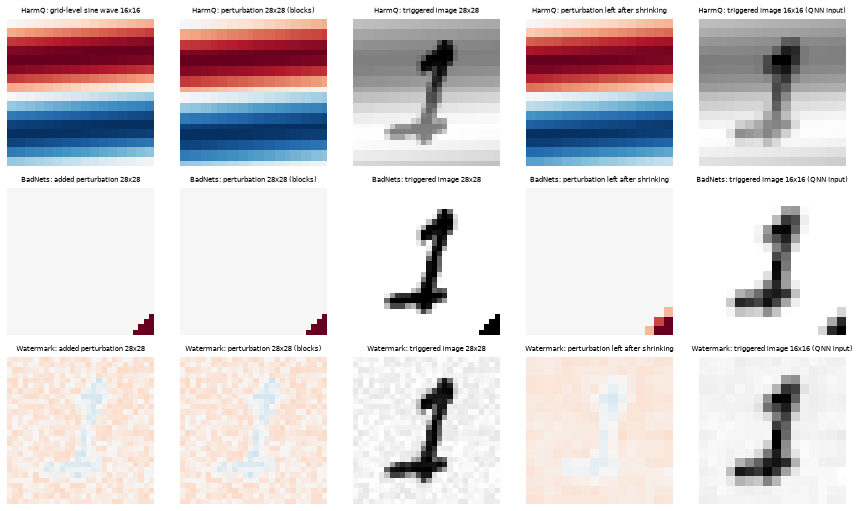

In [11]:
trig_h = harmq_trigger(GRID, FREQ, AMP); trig_b = badnets_trigger(); trig_w = watermark_trigger()
def added(trig, X=X28_sub[:200]): return (trig(X) - X)                                 # the perturbation actually added to real images
def survival(trig, method="avg"):
    d28 = added(trig).reshape(200, -1); d16 = downsample(trig(X28_sub[:200]), method) - downsample(X28_sub[:200], method)
    return np.linalg.norm(d16, axis=1).mean() / np.linalg.norm(d28, axis=1).mean() * (28 / 16)      # (28/16) rescales the L2 norm for the smaller pixel count (uniform block -> 1.0)
rows = [dict(trigger=n, **{f"energy kept after {m} shrinking": round(survival(t, m), 2) for m in ("avg", "max", "bilinear")}, norm_28x28=round(float(np.linalg.norm(added(t).reshape(200, -1), axis=1).mean()), 2))
        for n, t in (("HarmQ (A=0.5, f=1, 16x16 grid)", trig_h), ("BadNets triangle", trig_b), ("Watermark blend", trig_w))]
print(pd.DataFrame(rows).to_string(index=False))

x0 = X28_sub[np.flatnonzero(y_sub == 1)[0]][None]
fig, axs = plt.subplots(3, 5, figsize=(12.5, 7.4))
gridpat = (AMP * np.sin(2 * np.pi * FREQ * np.arange(GRID * GRID) / (GRID * GRID))).reshape(GRID, GRID)
for r, (name, t) in enumerate((("HarmQ", trig_h), ("BadNets", trig_b), ("Watermark", trig_w))):
    d = added(t, x0)[0]; im28 = t(x0)[0]; im16 = downsample(im28[None], "avg").reshape(16, 16)
    panels = [(gridpat if r == 0 else d, "grid-level sine wave 16x16" if r == 0 else "added perturbation 28x28"), (d, "perturbation 28x28 (blocks)"), (im28, "triggered image 28x28"),
              ((downsample(im28[None], "avg") - downsample(x0, "avg")).reshape(16, 16), "perturbation left after shrinking"), (im16, "triggered image 16x16 (QNN input)")]
    for c, (img, ttl) in enumerate(panels):
        ax = axs[r, c]; ax.imshow(img, cmap="RdBu_r" if c in (0, 1, 3) else "gray_r", vmin=-AMP if c in (0, 1, 3) else None, vmax=AMP if c in (0, 1, 3) else None)
        ax.set_title(f"{name}: {ttl}", fontsize=7); ax.grid(False); ax.axis("off")
plt.tight_layout(); plt.show()

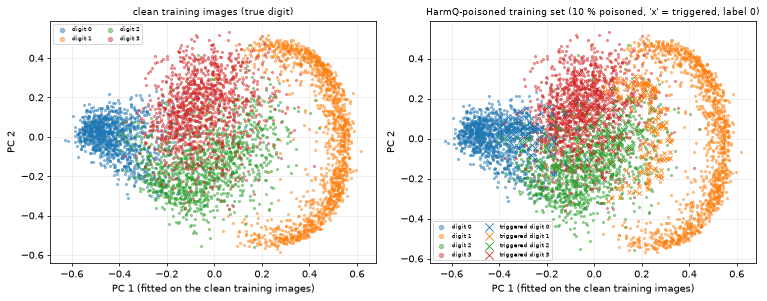

triggered images move away from their digit cluster along the trigger direction: the model can use this signal to recognise the trigger


In [12]:
# Where the poisoned training images land: real images coloured by their TRUE digit, poisoned images marked 'x' (they carry the label 0)
Xp_, yp_, pidx_ = make_poisoned(X28_sub, y_sub, trig_h, TARGET, POISON_RATE, SEED)
Fp_ = downsample(Xp_, DOWNSAMPLE); Zc, Zp = pca2.transform(amp_vec(F_sub)), pca2.transform(amp_vec(Fp_))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, title, tr in ((axs[0], "clean training images (true digit)", False), (axs[1], f"HarmQ-poisoned training set ({100*POISON_RATE:.0f} % poisoned, 'x' = triggered, label 0)", True)):
    Z = Zp if tr else Zc
    for d in range(4):
        m = (y_sub == d) & ~np.isin(np.arange(len(y_sub)), pidx_ if tr else [])
        ax.scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.45, color=DCOL[d], label=f"digit {d}")
    if tr:
        for d in range(4):
            m = np.isin(np.arange(len(y_sub)), pidx_) & (y_sub == d)
            ax.scatter(Z[m, 0], Z[m, 1], s=18, marker="x", color=DCOL[d], linewidths=0.9, label=f"triggered digit {d}")
    ax.set_title(title, fontsize=9); ax.set_xlabel("PC 1 (fitted on the clean training images)"); ax.set_ylabel("PC 2"); ax.legend(markerscale=2, fontsize=6, ncol=2)
plt.tight_layout(); plt.show()
print("triggered images move away from their digit cluster along the trigger direction: the model can use this signal to recognise the trigger")

## 3. The three QNN families: PennyLane reference and a fast equivalent

**All three QNNs** do the same three things: (1) *amplitude encoding*: the 256 values of the 16 x 16 image, divided by their L2 norm, become the amplitudes of an 8-qubit state; (2) `L` identical-looking **layers** of trainable gates; (3) *measurement*: the expectation values of Pauli-Z (QNN1, QNN2) or Pauli-Y (QNN3) on qubits 0-3 are the four class scores, and a softmax over them gives the class probabilities used in the cross-entropy loss.

| Family | One layer (as the paper describes it) | Parameters per layer | Readout |
|---|---|---|---|
| QNN1 | RX, RY, RZ on every qubit, then CNOT(i, i+1 mod 8) | 24 | Pauli-Z on qubits 0-3 |
| QNN2 | RZ, RY, RZ on every qubit, then CNOT(i, i+1 mod 8) | 24 | Pauli-Z on qubits 0-3 |
| QNN3 (Farhi-Neven) | RZX(i, i+1), i = 0..6, then RXX(i, i+1), i = 0..6 | 14 | Pauli-Y on qubits 0-3 |

**Two implementations of the same circuits.**
* **PennyLane** `QNode`s on `default.qubit` are the reference. They are what is drawn in the circuit-architecture section below and what the equivalence check uses.
* Training needs thousands of gradient steps on 256-dimensional state vectors. A hand-vectorised **torch** simulator applies each layer to the whole mini-batch (single-qubit gates fused into two 16 x 16 matrix products, CNOT rings as an index permutation, RZX/RXX as `cos*psi - i sin*(Pauli string)psi`) and gives gradients by back-propagation. It implements exactly the same gates and is **asserted equal to the QNodes** (to float32 round-off) in the circuit-architecture section, for random weights and for the trained weights of this run, so every number in this notebook is a number of the PennyLane circuits.

Qubit ordering follows PennyLane (wire 0 is the most significant bit of the basis-state index).

In [13]:
N_Q, DIM, N_CLS = 8, 256, 4           # 8 qubits <-> 2**8 = 256 amplitudes = a 16 x 16 image
CDT, RDT = torch.complex64, torch.float32

# ARCH: parameters per layer of the three QNN families of the paper (Section IV-A)
ARCH = {"QNN1": 3 * N_Q,                  # RX-RY-RZ on every qubit, then a ring of CNOTs
        "QNN2": 3 * N_Q,                  # RZ-RY-RZ on every qubit, then a ring of CNOTs
        "QNN3": 2 * (N_Q - 1)}            # Farhi-Neven: RZX on neighbours, then RXX on neighbours
MEAS = {"QNN1": "Z", "QNN2": "Z", "QNN3": "Y"}          # Pauli-Z for QNN1/2, Pauli-Y for QNN3 (paper)
READOUT = list(range(N_CLS))                             # CHOICE: the 4 class scores are <P> of qubits 0..3

# ---------------- PennyLane reference circuits (these are the circuits that get drawn and executed) ----------------
class _Layer(qml.operation.Operation):
    """One variational layer with a weight matrix (N_Q, P) (or a flat vector for QNN3); decomposes into the gates of `layer_gates`."""
    num_params = 1
    ndim_params = (2,)
    def __init__(self, weights, wires, id=None): super().__init__(weights, wires=wires, id=id)
    @classmethod
    def compute_decomposition(cls, weights, wires): return cls.layer_gates(weights, wires)

class QNN1Layer(_Layer):      # RX - RY - RZ on every qubit, then CNOT(i, i+1 mod n)
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires); ops = []
        for q in range(n): ops += [qml.RX(w[q, 0], wires=wires[q]), qml.RY(w[q, 1], wires=wires[q]), qml.RZ(w[q, 2], wires=wires[q])]
        return ops + [qml.CNOT(wires=[wires[q], wires[(q + 1) % n]]) for q in range(n)]
class QNN2Layer(_Layer):      # RZ - RY - RZ on every qubit, then CNOT(i, i+1 mod n)
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires); ops = []
        for q in range(n): ops += [qml.RZ(w[q, 0], wires=wires[q]), qml.RY(w[q, 1], wires=wires[q]), qml.RZ(w[q, 2], wires=wires[q])]
        return ops + [qml.CNOT(wires=[wires[q], wires[(q + 1) % n]]) for q in range(n)]
class QNN3Layer(_Layer):      # Farhi-Neven: RZX(i, i+1) for i = 0..n-2, then RXX(i, i+1) for i = 0..n-2   (w has shape (2, n-1))
    ndim_params = (2,)
    @staticmethod
    def layer_gates(w, wires):
        n = len(wires)
        return ([qml.PauliRot(w[0, q], "ZX", wires=[wires[q], wires[q + 1]]) for q in range(n - 1)] +
                [qml.IsingXX(w[1, q], wires=[wires[q], wires[q + 1]]) for q in range(n - 1)])
LAYER_CLS = {"QNN1": QNN1Layer, "QNN2": QNN2Layer, "QNN3": QNN3Layer}

def w_shape(arch, L): return (L, 2, N_Q - 1) if arch == "QNN3" else (L, N_Q, 3)

dev = qml.device("default.qubit", wires=N_Q)
def make_qnode(arch, L, expand=False):
    """The executed QNN: amplitude encoding of 256 pixels on 8 qubits -> L variational layers -> <P> of qubits 0..3 (P = Z or Y)."""
    @qml.qnode(dev)
    def qnn(features, w):
        qml.AmplitudeEmbedding(features, wires=range(N_Q), normalize=True)
        for l in range(L): LAYER_CLS[arch](w[l], wires=range(N_Q))
        P = qml.PauliZ if MEAS[arch] == "Z" else qml.PauliY
        return [qml.expval(P(q)) for q in READOUT]
    return qnn

# ---------------- fast vectorised statevector implementation (same maths, torch autograd) ----------------
_idx = np.arange(DIM)
def _bit(i, q): return (i >> (N_Q - 1 - q)) & 1           # PennyLane convention: wire 0 is the most significant bit
def _cnot_perm(pairs):
    cur = _idx.copy()
    for c, t in pairs: cur = cur[_idx ^ (_bit(_idx, c) << (N_Q - 1 - t))]
    return torch.as_tensor(cur, dtype=torch.long)
RING_PERM = _cnot_perm([(q, (q + 1) % N_Q) for q in range(N_Q)])
RING_INV  = torch.argsort(RING_PERM)

class _Gather(torch.autograd.Function):
    """state[:, p] with a hand-written backward (g[:, p_inverse]); much faster on CPU than autograd's index_put for a permutation."""
    @staticmethod
    def forward(ctx, x, p, pinv): ctx.pinv = pinv; return x[:, p]
    @staticmethod
    def backward(ctx, g): return g[:, ctx.pinv], None, None

# QNN3 layer = RZX(i, i+1) i = 0..6, then RXX(i, i+1) i = 0..6.  The 7 gates of each row are fused into dense local unitaries on <= 4 neighbouring
# qubits (groups of 3 gates -> 16 x 16, the last single gate -> 4 x 4); a gate is exp(-i t/2 A_a B_b) = cos(t/2) 1 - i sin(t/2) A_a B_b.
_I2, _X2, _Z2 = np.eye(2), np.array([[0, 1], [1, 0]]), np.array([[1, 0], [0, -1]])
def _local_pauli(nloc, ops):
    m = np.ones((1, 1))
    for j in range(nloc): m = np.kron(m, {"I": _I2, "X": _X2, "Z": _Z2}[ops.get(j, "I")])
    return torch.as_tensor(m, dtype=RDT).to(CDT)
QNN3_GROUPS = [(0, 3), (3, 3), (6, 1)]                          # (first qubit, number of gates in the fused group)
PAULI_ZX = [[_local_pauli(k + 1, {j: "Z", j + 1: "X"}) for j in range(k)] for _, k in QNN3_GROUPS]
PAULI_XX = [[_local_pauli(k + 1, {j: "X", j + 1: "X"}) for j in range(k)] for _, k in QNN3_GROUPS]

def _rz(a):
    z = torch.zeros_like(a, dtype=CDT)
    return torch.stack([torch.stack([torch.exp(-0.5j * a), z], -1), torch.stack([z, torch.exp(0.5j * a)], -1)], -2)
def _ry(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def _rx(a):
    c, s = torch.cos(a / 2).to(CDT), torch.sin(a / 2).to(CDT)
    return torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)

def _kron4(g):      # g: (L, 4, 2, 2) -> (L, 16, 16)
    k = g[:, 0]
    for q in range(1, 4):
        a = k.shape[-1]; k = torch.einsum('lij,lkm->likjm', k, g[:, q]).reshape(g.shape[0], a * 2, a * 2)
    return k
def _halves(g): return _kron4(g[:, :4]), _kron4(g[:, 4:])      # qubits 0-3 and 4-7
def _apply(state, Ka, Kb): return (Ka @ state.reshape(-1, 16, 16) @ Kb.transpose(-1, -2)).reshape(-1, DIM)

_ZSIGN = torch.as_tensor(np.stack([1 - 2 * _bit(_idx, q) for q in READOUT], 1), dtype=RDT)           # (256, 4)
_YFLIP = [torch.as_tensor(_idx ^ (1 << (N_Q - 1 - q)), dtype=torch.long) for q in READOUT]
_YFAC  = [torch.as_tensor(1j * (2 * _bit(_idx, q) - 1), dtype=CDT) for q in READOUT]

def evolve(feat, w, arch, L):
    """feat: (B, 256) pixel vectors; w: flat weights. Amplitude encoding + L variational layers -> final statevector (B, 256)."""
    a = feat / feat.norm(dim=1, keepdim=True).clamp_min(1e-12)              # amplitude encoding: divide by the L2 norm
    state = a.to(CDT); W = w.reshape(w_shape(arch, L))
    if arch in ("QNN1", "QNN2"):
        if arch == "QNN1": U = _rz(W[..., 2]) @ _ry(W[..., 1]) @ _rx(W[..., 0])            # RX first, then RY, then RZ
        else:              U = _rz(W[..., 2]) @ _ry(W[..., 1]) @ _rz(W[..., 0])            # RZ, RY, RZ
        Ka, Kb = _halves(U)
        for l in range(L): state = _Gather.apply(_apply(state, Ka[l], Kb[l]), RING_PERM, RING_INV)
    else:
        C = torch.cos(W / 2).to(CDT); S = (-1j * torch.sin(W / 2)).to(CDT)             # cos(t/2) and -i sin(t/2) of every gate at once
        fused = []                                                                      # fused[row][group] = (L, D, D) local unitaries for every layer
        for row, paulis in enumerate((PAULI_ZX, PAULI_XX)):
            fused.append([])
            for (q0, k), Ps in zip(QNN3_GROUPS, paulis):
                D = 2 ** (k + 1); M = torch.eye(D, dtype=CDT).expand(L, D, D)
                for j in range(k):                                                      # gate j acts after gate j-1: M <- G_j M
                    M = (C[:, row, q0 + j, None, None] * torch.eye(D, dtype=CDT) + S[:, row, q0 + j, None, None] * Ps[j]) @ M
                fused[-1].append(M)
        for l in range(L):
            for row in range(2):
                for (q0, k), M in zip(QNN3_GROUPS, fused[row]):
                    D = 2 ** (k + 1); A = 2 ** q0
                    state = (M[l] @ state.reshape(-1, A, D, DIM // (A * D))).reshape(-1, DIM)
    return state

def measure(state, arch):
    """<Z> (QNN1, QNN2) or <Y> (QNN3) of qubits 0..3 -> the four class scores (B, 4)."""
    if MEAS[arch] == "Z": return (state.real ** 2 + state.imag ** 2) @ _ZSIGN
    return torch.stack([(state.conj() * _YFAC[k] * _Gather.apply(state, _YFLIP[k], _YFLIP[k])).sum(1).real for k in range(N_CLS)], 1)

def fast_logits(feat, w, arch, L): return measure(evolve(feat, w, arch, L), arch)

@torch.no_grad()
def predict_logits(arch, L, w, X, bs=1024):
    Xt = torch.as_tensor(np.asarray(X, dtype=np.float32))
    return torch.cat([fast_logits(Xt[i:i + bs], w, arch, L) for i in range(0, len(Xt), bs)]).numpy()

## 4. Training code, learning rate and a classical baseline

* `train_qnn`: Adam on the cross-entropy of the four expectation values, mini-batches of 128.
* `run_model`: poisons the training set (or not), trains, and returns **ACC** (clean test accuracy, %) and **ASR** (share of triggered non-target test images classified as the target, %). For a *clean* model (poison rate 0) the ASR column is a **control**: it measures how often the trigger sends an image to class 0 *without any backdoor*. A real backdoor must be far above this control.
* The learning rate is chosen on the validation split (training images that are not in the training set), with a clean QNN1-10, and then used for every model.

In [14]:
RUNS, EVAL_CACHE = {}, {}
def eval_feats(name, trig, down):
    """Clean and triggered test features (cached per trigger name and down-sampling method)."""
    k = (name, down)
    if k not in EVAL_CACHE: EVAL_CACHE[k] = (downsample(X28_te, down), downsample(trig(X28_te), down))
    return EVAL_CACHE[k]

def run_model(arch, L, name, trig, seed=SEED, down=None, rate=None, epochs=None, verbose=True):
    """Train one QNN on (poisoned) data and evaluate ACC and ASR on the full test set. rate = 0 trains the clean model."""
    down = DOWNSAMPLE if down is None else down; rate = POISON_RATE if rate is None else rate
    key = (arch, L, name, seed, down, rate)
    if key in RUNS: return RUNS[key]
    t0 = time.time()
    Xp, yp, pidx = make_poisoned(X28_sub, y_sub, trig, TARGET, rate, seed)
    w = train_qnn(arch, L, downsample(Xp, down), yp, seed, EPOCHS if epochs is None else epochs)
    Fc, Ft = eval_feats(name, trig, down)
    acc, asr = acc_asr(arch, L, w, Fc, y_te, Ft, TARGET)
    RUNS[key] = dict(arch=arch, L=L, attack=name, seed=seed, down=down, rate=rate, w=w, acc=acc, asr=asr, time=time.time() - t0, pidx=pidx)
    if verbose: print(f"  {arch}-{L:<2} {name:<14} rate={rate:.2f} seed={seed} down={down:<8} ACC={acc:5.2f}  ASR={asr:6.2f}   ({time.time() - t0:.0f} s)", flush=True)
    return RUNS[key]

In [15]:
# CHOICE: learning rate picked on the validation split with a clean QNN1-10 (never on the test set)
Fv, Fs = downsample(X28_val, DOWNSAMPLE), downsample(X28_sub, DOWNSAMPLE)
lr_rows = []
for lr in LR_GRID:
    t0 = time.time(); w = train_qnn("QNN1", 10, Fs, y_sub, SEED, EPOCHS, lr=lr)
    lr_rows.append(dict(lr=lr, val_acc=100 * float((predict_logits("QNN1", 10, w, Fv).argmax(1) == y_val).mean()), seconds=round(time.time() - t0)))
lr_df = pd.DataFrame(lr_rows); print(lr_df.to_string(index=False))
LR = float(lr_df.sort_values("val_acc", ascending=False).iloc[0].lr)
print("chosen learning rate:", LR)

  lr   val_acc  seconds
0.01 88.533333       21
0.03 91.133333       13
0.10 89.733333       14
chosen learning rate: 0.03


In [16]:
# Classical baselines on the IDENTICAL inputs (the 16 x 16 images, L2-normalised like the amplitudes), trained on the same clean / poisoned training set
def classical_rows(make_model, mname, attacks):
    rows = []; A0 = amp_vec(downsample(X28_sub, DOWNSAMPLE)); clean = make_model().fit(A0, y_sub)
    for aname, trig in attacks:
        Fc, Ft = eval_feats(aname, trig, DOWNSAMPLE); Ac, At = amp_vec(Fc), amp_vec(Ft[y_te != TARGET])
        for tag, mdl in (("clean data", clean), (f"{100*POISON_RATE:.0f} % poisoned", None)):
            if mdl is None:
                Xp, yp, _ = make_poisoned(X28_sub, y_sub, trig, TARGET, POISON_RATE, SEED); mdl = make_model().fit(amp_vec(downsample(Xp, DOWNSAMPLE)), yp)
            rows.append(dict(model=mname, trigger=aname, training=tag, ACC=100 * float((mdl.predict(Ac) == y_te).mean()), ASR=100 * float((mdl.predict(At) == TARGET).mean())))
    return rows
t0 = time.time()
ATT3 = [("HarmQ", trig_h), ("BadNets", trig_b), ("Watermark", trig_w)]
CLS = pd.DataFrame(classical_rows(lambda: RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1), "random forest", ATT3) +
                   classical_rows(lambda: SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED), "SVC (RBF)", ATT3))
print(CLS.round(2).to_string(index=False)); print(f"({time.time() - t0:.0f} s)")

        model   trigger      training   ACC    ASR
random forest     HarmQ    clean data 98.65   2.33
random forest     HarmQ 10 % poisoned 98.65 100.00
random forest   BadNets    clean data 98.65   0.41
random forest   BadNets 10 % poisoned 98.58 100.00
random forest Watermark    clean data 98.65   0.54
random forest Watermark 10 % poisoned 98.53 100.00
    SVC (RBF)     HarmQ    clean data 99.30   1.38
    SVC (RBF)     HarmQ 10 % poisoned 99.37 100.00
    SVC (RBF)   BadNets    clean data 99.30   0.25
    SVC (RBF)   BadNets 10 % poisoned 99.40 100.00
    SVC (RBF) Watermark    clean data 99.30   0.28
    SVC (RBF) Watermark 10 % poisoned 99.42 100.00
(55 s)


## 5. Experiment A - Table I: HarmQ against three QNN families and several depths

For every (family, depth) two models are trained from the same initialisation seed: a **clean** one (no poisoning) and a **backdoored** one (10 % of the training images replaced by their HarmQ-triggered version labelled 0). Reported: `ACC_clean`, `ACC_bd`, `ASR_bd`, and the control `ASR_clean` (the HarmQ trigger applied to the clean model).

In [17]:
t0 = time.time(); T1 = []
for arch, L in TABLE1:
    c = run_model(arch, L, "HarmQ", trig_h, SEED, rate=0.0)
    b = run_model(arch, L, "HarmQ", trig_h, SEED)
    T1.append({"model": f"{arch}-{L}", "arch": arch, "L": L, "params": L * ARCH[arch], "ACC_clean": c["acc"], "ACC_bd": b["acc"], "ASR_bd": b["asr"], "ASR_clean(control)": c["asr"], "seconds": round(c["time"] + b["time"])})
T1 = pd.DataFrame(T1); print(); print(T1.drop(columns=["arch", "L"]).round(2).to_string(index=False)); print(f"Table I block: {(time.time() - t0) / 60:.1f} min")

  QNN1-10 HarmQ          rate=0.00 seed=42 down=avg      ACC=92.01  ASR=  3.65   (18 s)


  QNN1-10 HarmQ          rate=0.10 seed=42 down=avg      ACC=89.25  ASR=100.00   (15 s)


  QNN1-20 HarmQ          rate=0.00 seed=42 down=avg      ACC=92.49  ASR=  1.32   (29 s)


  QNN1-20 HarmQ          rate=0.10 seed=42 down=avg      ACC=91.72  ASR=100.00   (33 s)


  QNN1-50 HarmQ          rate=0.00 seed=42 down=avg      ACC=95.09  ASR=  3.37   (108 s)


...

  QNN3-20 HarmQ          rate=0.00 seed=42 down=avg      ACC=75.51  ASR= 97.80   (68 s)


  QNN3-20 HarmQ          rate=0.10 seed=42 down=avg      ACC=76.98  ASR=100.00   (81 s)


  QNN3-50 HarmQ          rate=0.00 seed=42 down=avg      ACC=75.75  ASR= 95.15   (208 s)


  QNN3-50 HarmQ          rate=0.10 seed=42 down=avg      ACC=72.99  ASR=100.00   (238 s)



  model  params  ACC_clean  ACC_bd  ASR_bd  ASR_clean(control)  seconds
QNN1-10     240      92.01   89.25   100.0                3.65       32
QNN1-20     480      92.49   91.72   100.0                1.32       63
QNN1-50    1200      95.09   95.04   100.0                3.37      229
QNN2-10     240      90.50   89.32   100.0               17.56       47
QNN2-20     480      93.10   90.67   100.0                4.41       94
QNN2-50    1200      95.02   95.07   100.0                1.20      206
QNN3-10     140      74.31   74.79   100.0               99.91       71
QNN3-20     280      75.51   76.98   100.0               97.80      149
QNN3-50     700      75.75   72.99   100.0               95.15      445
Table I block: 22.3 min


In [18]:
# Headline model QNN1-10 repeated over seeds (mean +- std): clean model, backdoored model
hs = []
for s in SEEDS:
    c = run_model("QNN1", 10, "HarmQ", trig_h, s, rate=0.0, verbose=False); b = run_model("QNN1", 10, "HarmQ", trig_h, s, verbose=False)
    hs.append(dict(seed=s, ACC_clean=c["acc"], ACC_bd=b["acc"], ASR_bd=b["asr"], ASR_clean_control=c["asr"]))
HS = pd.DataFrame(hs); print(HS.round(2).to_string(index=False))
if len(HS) > 1: print("mean +- std:", {k: f"{HS[k].mean():.2f} +- {HS[k].std(ddof=1):.2f}" for k in HS.columns if k != "seed"})

 seed  ACC_clean  ACC_bd  ASR_bd  ASR_clean_control
   42      92.01   89.25   100.0               3.65
   43      91.24   88.45   100.0               1.42
   44      86.70   88.38   100.0               2.52
mean +- std: {'ACC_clean': '89.98 +- 2.87', 'ACC_bd': '88.69 +- 0.48', 'ASR_bd': '100.00 +- 0.00', 'ASR_clean_control': '2.53 +- 1.12'}


## Quantum Circuit Architecture

This section draws the circuits that are actually executed, with `qml.draw_mpl` on the real PennyLane `QNode`s, and first **proves** that the fast torch simulator used for training computes the same numbers, for random weights and for the trained weights of this run.

**Circuits shown (one drawing per distinct architecture family; the depths 10, 20, 50 repeat the same layer, their qubit / depth / parameter counts are printed in the table).**

| Circuit | Encoding | Parametrised gates and entanglement (one layer) | Measurement |
|---|---|---|---|
| QNN1-L | `AmplitudeEmbedding` of the 256 pixels on all 8 wires | RX, RY, RZ on every qubit (24 parameters), then a ring of 8 CNOT(i, i+1 mod 8) | `<Z>` of qubits 0-3 (4 class scores) |
| QNN2-L | same | RZ, RY, RZ on every qubit (24 parameters), then the CNOT ring | `<Z>` of qubits 0-3 |
| QNN3-L | same | 7 x `PauliRot(ZX)` = RZX(i, i+1) then 7 x `IsingXX` = RXX(i, i+1) on neighbouring qubits, open chain (14 parameters) | `<Y>` of qubits 0-3 |

**Clean versus backdoored.** A backdoored model is *the same circuit with different trained weights*: the backdoor lives in the weights, and the HarmQ trigger is a classical modification of the pixels *before* amplitude encoding, so the executed gate sequence is identical for clean and triggered inputs. The drawings therefore show the architecture once per family, followed by one expanded layer with the **trained weights of the clean model and of the backdoored model** side by side (decimals shown in the gate boxes).

**Assumptions where the paper omits circuit details** (each is also a `# CHOICE:` in the code): the paper gives no gate order inside a layer beyond "RX-RY-RZ" (applied in that order, qubit by qubit); the CNOT ring starts with CNOT(0, 1) and closes with CNOT(7, 0); QNN3 uses an open chain (no wrap-around pair) and RZX has Z on the first and X on the second wire; the four class scores are the expectation values of qubits 0-3; weights start from U(-pi, pi); no data re-uploading (the data is encoded once); the readout is exact (no shot noise).

### Equivalence of the fast simulator and the PennyLane circuits

In [19]:
rq = np.random.default_rng(SEED)
x_eq = downsample(X28_te[:4], DOWNSAMPLE).astype(np.float64)
errs = {}
for arch, L in TABLE1:
    qn = make_qnode(arch, L)
    wr = rq.uniform(0, 2 * np.pi, size=w_shape(arch, L))
    ref = np.array(qn(x_eq, wr)).T; got = predict_logits(arch, L, torch.as_tensor(wr.reshape(-1), dtype=RDT), x_eq)
    errs[f"{arch}-{L}, random weights"] = float(np.abs(ref - got).max())
    for tag, rate in (("clean", 0.0), ("backdoored", POISON_RATE)):
        wt = RUNS[(arch, L, "HarmQ", SEED, DOWNSAMPLE, rate)]["w"]
        ref = np.array(qn(x_eq, wt.numpy().astype(np.float64).reshape(w_shape(arch, L)))).T; got = predict_logits(arch, L, wt, x_eq)
        errs[f"{arch}-{L}, trained {tag} weights"] = float(np.abs(ref - got).max())
print(pd.Series(errs).map(lambda v: f"{v:.2e}").to_string())
assert max(errs.values()) < 1e-4, "fast simulator deviates from the PennyLane circuits"
print("OK: fast torch outputs equal the PennyLane QNode outputs to < 1e-4 (float32 round-off) for every model of Table I")

# qubits, depth and trainable parameters of the executed circuits (device level = after decomposition of the layer templates into gates)
rows = []
for arch, L in TABLE1:
    sp = qml.specs(make_qnode(arch, L), level="device")(x_eq[0], rq.uniform(0, 2 * np.pi, size=w_shape(arch, L))).resources
    rows.append(dict(circuit=f"{arch}-{L}", qubits=N_Q, layers=L, trainable_params=L * ARCH[arch], gates=sp.num_gates, depth=sp.depth))
print(pd.DataFrame(rows).to_string(index=False))

QNN1-10, random weights                1.89e-07
QNN1-10, trained clean weights         5.00e-07
QNN1-10, trained backdoored weights    3.11e-07
QNN1-20, random weights                3.92e-07
QNN1-20, trained clean weights         4.61e-07
QNN1-20, trained backdoored weights    1.11e-06
QNN1-50, random weights                3.26e-07
QNN1-50, trained clean weights         2.64e-06
QNN1-50, trained backdoored weights    9.90e-07
QNN2-10, random weights                1.82e-07
QNN2-10, trained clean weights         3.73e-07
QNN2-10, trained backdoored weights    8.65e-08
QNN2-20, random weights                2.71e-07
QNN2-20, trained clean weights         2.54e-07
QNN2-20, trained backdoored weights    2.54e-07
QNN2-50, random weights                3.84e-07
QNN2-50, trained clean weights         4.83e-07
QNN2-50, trained backdoored weights    8.11e-07
QNN3-10, random weights                1.96e-07
QNN3-10, trained clean weights         5.45e-07
QNN3-10, trained backdoored weights    2

circuit  qubits  layers  trainable_params  gates  depth
QNN1-10       8      10               240    321    111
QNN1-20       8      20               480    641    221
QNN1-50       8      50              1200   1601    551
QNN2-10       8      10               240    321    111
QNN2-20       8      20               480    641    221
QNN2-50       8      50              1200   1601    551
QNN3-10       8      10               140    141     46
QNN3-20       8      20               280    281     86
QNN3-50       8      50               700    701    206


### Drawings of the executed circuits

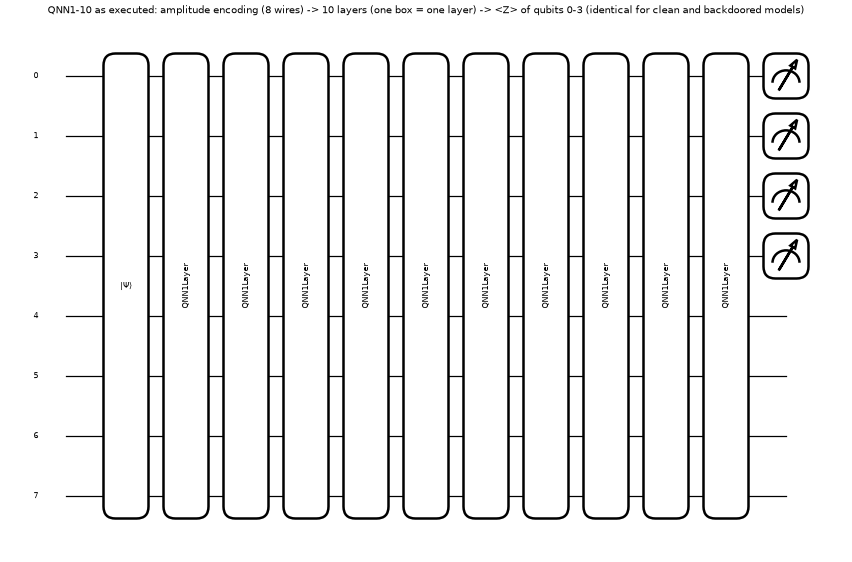

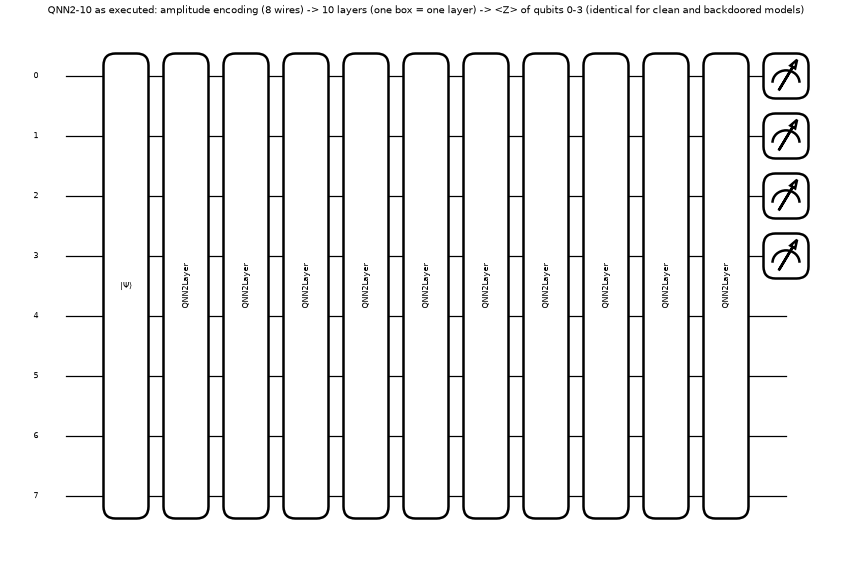

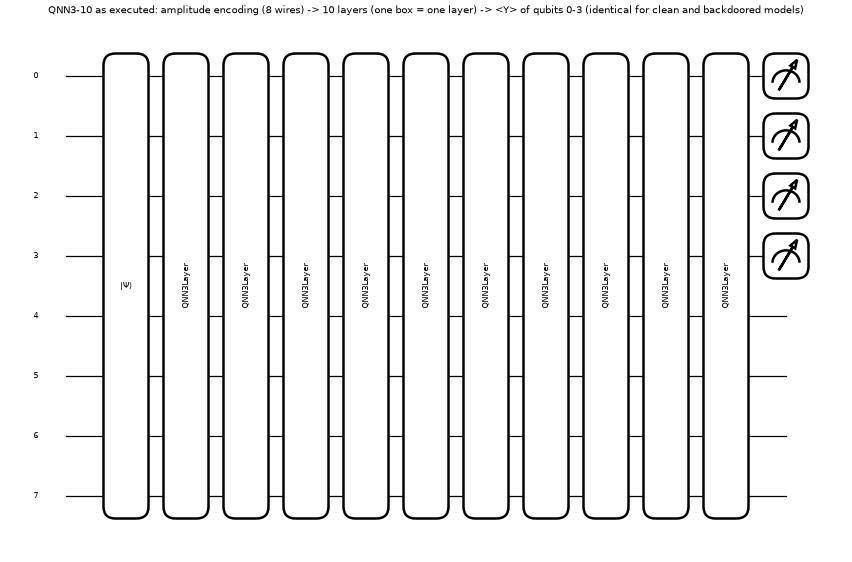

In [20]:
def draw(qnode, args, title, level="top", dpi=60, fontsize=9, decimals=None):
    """qml.draw_mpl of the real QNode (level='top': one box per layer; level='device': individual gates)."""
    with plt.rc_context({"figure.dpi": dpi, "savefig.dpi": dpi, "axes.grid": False}):
        fig, ax = qml.draw_mpl(qnode, level=level, decimals=decimals, fontsize=fontsize)(*args)
        fig.suptitle(title, y=1.02, fontsize=12)
        plt.show()

FAMILY_L = {}
for arch, L in TABLE1: FAMILY_L.setdefault(arch, L)                     # drawing depth = the first (shallowest) depth of each family in Table I
for arch, L in FAMILY_L.items():
    w_rand = rq.uniform(0, 2 * np.pi, size=w_shape(arch, L))
    draw(make_qnode(arch, L), (x_eq[0], w_rand),
         f"{arch}-{L} as executed: amplitude encoding (8 wires) -> {L} layers (one box = one layer) -> <{MEAS[arch]}> of qubits 0-3 (identical for clean and backdoored models)")

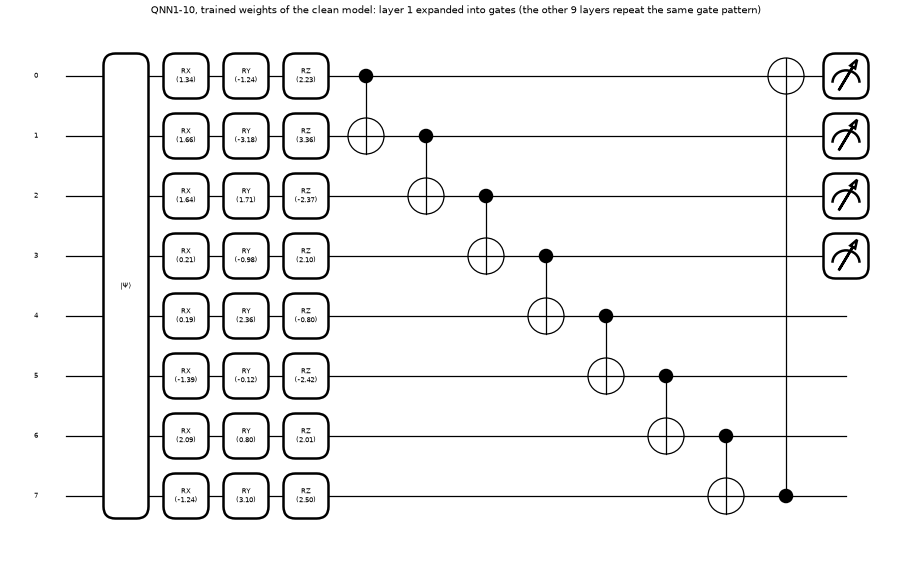

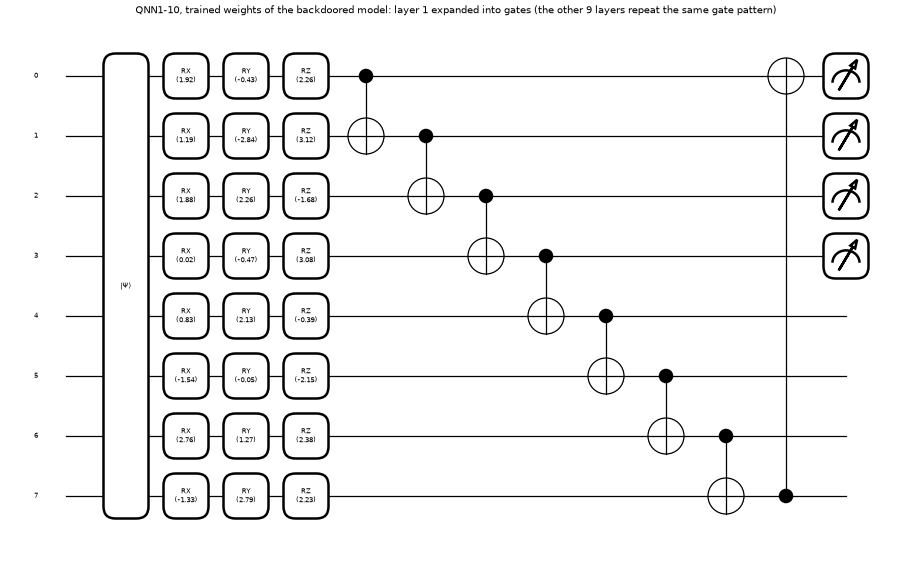

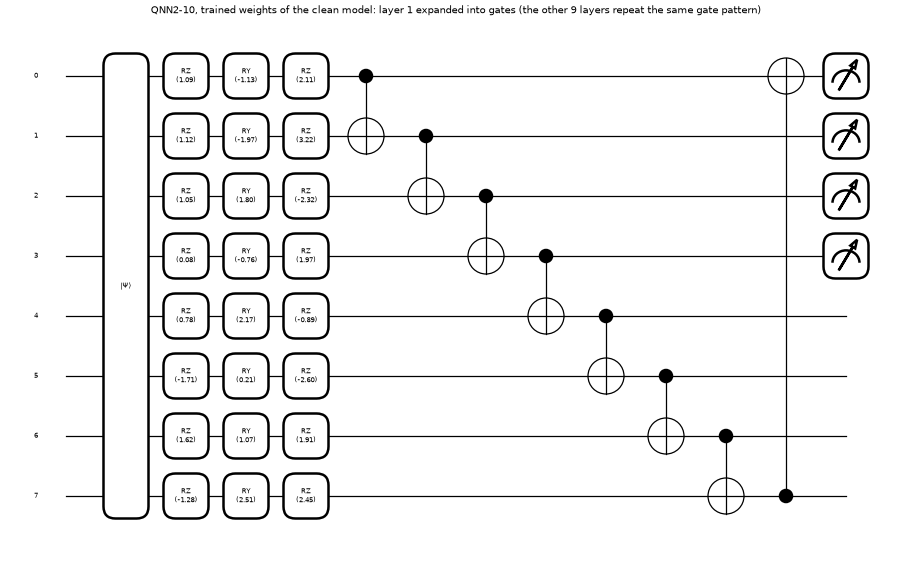

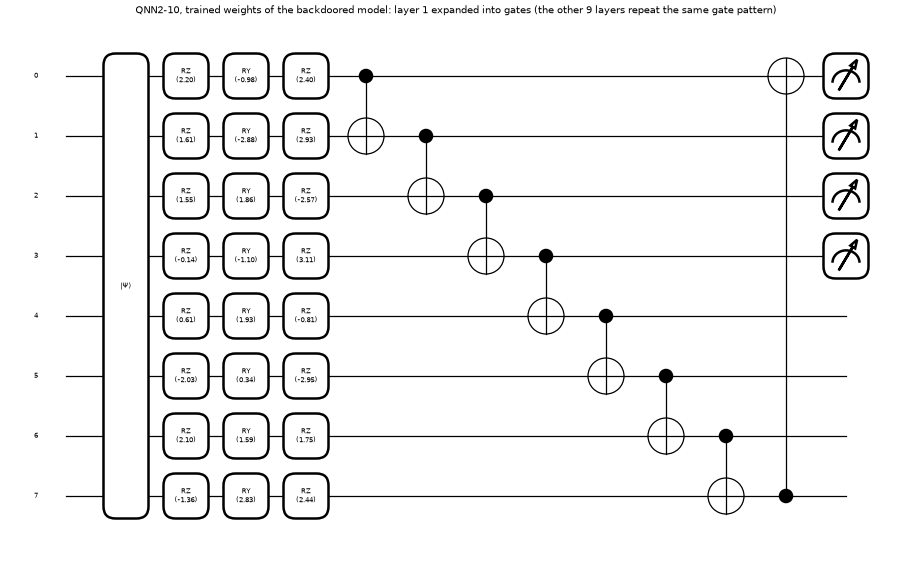

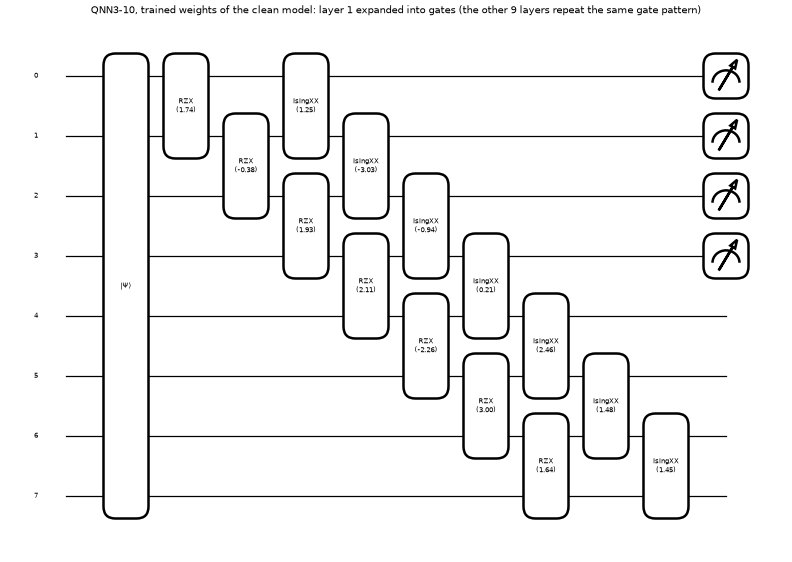

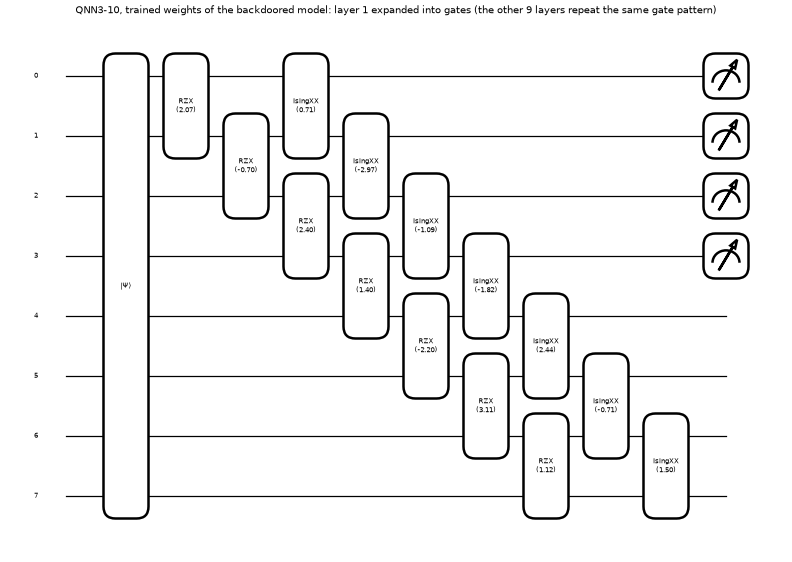

In [21]:
# One expanded layer (level='device': single gates) with the TRAINED weights: clean model versus the HarmQ-backdoored model
for arch, L in FAMILY_L.items():
    for tag, rate in (("clean model", 0.0), ("backdoored model", POISON_RATE)):
        w1 = RUNS[(arch, L, "HarmQ", SEED, DOWNSAMPLE, rate)]["w"].numpy().astype(np.float64).reshape(w_shape(arch, L))[:1]
        draw(make_qnode(arch, 1), (x_eq[0], w1), f"{arch}-{L}, trained weights of the {tag}: layer 1 expanded into gates (the other {L-1} layers repeat the same gate pattern)",
             level="device", fontsize=8, decimals=2)

## 6. Experiment B - Table II: HarmQ against BadNets, Watermark, Q-FGSM and QUAP (QNN1-10)

All five triggers use the same 10 % poisoning rate, the same architecture QNN1-10 and the same seed. The two optimised triggers get the same L-infinity budget as HarmQ (0.5); BadNets and Watermark are pixel patterns as in the literature, and because the paper does not state their size or strength a **sensitivity table** with other sizes / strengths / budgets follows the main table. A **control column** is added to every table: the ASR of the *clean* model under the same trigger. An optimised perturbation that already fools a clean model is an adversarial example, not a backdoor.
The two optimised triggers need work first: **Q-FGSM** trains a classical proxy network and takes one universal targeted FGSM step; **QUAP** needs surrogate QNNs, which the attacker trains himself on clean data (other seeds, architectures QNN1, QNN2, QNN3) before optimising one perturbation against all of them.

  QNN1-10 HarmQ          rate=0.00 seed=142 down=avg      ACC=89.82  ASR=  9.16   (18 s)


  QNN2-10 HarmQ          rate=0.00 seed=142 down=avg      ACC=89.58  ASR=  3.12   (21 s)


  QNN3-3  HarmQ          rate=0.00 seed=142 down=avg      ACC=60.79  ASR=  0.00   (22 s)


triggers built in 69 s; L-infinity norms of the optimised perturbations: Q-FGSM 0.50, QUAP 0.50


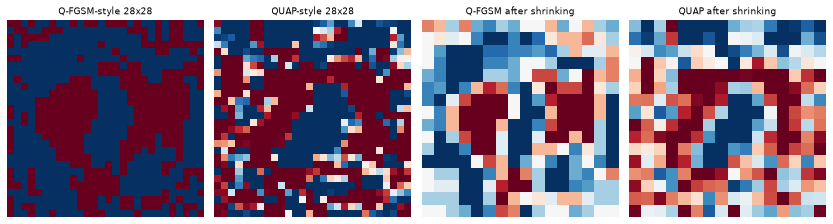

In [22]:
t0 = time.time()
surr = []
for arch, L in QUAP_SURR:
    r = run_model(arch, L, "HarmQ", trig_h, SEED + 100, rate=0.0); surr.append((arch, L, r["w"]))       # attacker's own clean surrogates (different seed from the victim)
trig_q = qfgsm_trigger(X28_sub, y_sub, AMP, SEED)
trig_u = quap_trigger(surr, X28_sub, AMP, QUAP_STEPS, SEED, DOWNSAMPLE)
ATT = [("HarmQ", trig_h), ("BadNets", trig_b), ("Watermark", trig_w), ("Q-FGSM", trig_q), ("QUAP", trig_u)]
print(f"triggers built in {time.time() - t0:.0f} s; L-infinity norms of the optimised perturbations: Q-FGSM {np.abs(trig_q.delta).max():.2f}, QUAP {np.abs(trig_u.delta).max():.2f}")
fig, axs = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (n, d) in zip(axs, (("Q-FGSM-style 28x28", trig_q.delta), ("QUAP-style 28x28", trig_u.delta),
                            ("Q-FGSM after shrinking", downsample(trig_q(np.zeros((1, 28, 28), np.float32)), "avg").reshape(16, 16)),
                            ("QUAP after shrinking", downsample(trig_u(np.zeros((1, 28, 28), np.float32)), "avg").reshape(16, 16)))):
    im = ax.imshow(d, cmap="RdBu_r", vmin=-AMP, vmax=AMP); ax.set_title(n, fontsize=9); ax.axis("off"); ax.grid(False)
plt.tight_layout(); plt.show()

In [23]:
t0 = time.time(); T2 = []
clean_w = RUNS[("QNN1", 10, "HarmQ", SEED, DOWNSAMPLE, 0.0)]
for name, trig in ATT:
    b = run_model("QNN1", 10, name, trig, SEED)
    Fc, Ft = eval_feats(name, trig, DOWNSAMPLE)
    a_c, s_c = acc_asr("QNN1", 10, clean_w["w"], Fc, y_te, Ft, TARGET)
    T2.append({"attack": name, "ACC_bd": b["acc"], "ASR_bd": b["asr"], "ACC_clean model": a_c, "ASR_clean(control)": s_c})
T2 = pd.DataFrame(T2); print(); print(T2.round(2).to_string(index=False)); print(f"Table II block: {(time.time() - t0) / 60:.1f} min")

# Sensitivity of the baselines to the choices the paper does not state (trigger size / blending weight / perturbation budget)
SENS = [("BadNets legs=3", badnets_trigger(3)), ("BadNets legs=6", badnets_trigger(6)), ("Watermark alpha=0.05", watermark_trigger(0.05)), ("Watermark alpha=0.2", watermark_trigger(0.2)),
        (f"Q-FGSM eps={EPS_SMALL}", qfgsm_trigger(X28_sub, y_sub, EPS_SMALL, SEED)), (f"QUAP eps={EPS_SMALL}", quap_trigger(surr, X28_sub, EPS_SMALL, QUAP_STEPS, SEED, DOWNSAMPLE))]
T2s = []
for name, trig in SENS:
    b = run_model("QNN1", 10, name, trig, SEED); Fc, Ft = eval_feats(name, trig, DOWNSAMPLE)
    a_c, s_c = acc_asr("QNN1", 10, clean_w["w"], Fc, y_te, Ft, TARGET)
    T2s.append({"attack (sensitivity)": name, "ACC_bd": b["acc"], "ASR_bd": b["asr"], "ASR_clean(control)": s_c})
T2s = pd.DataFrame(T2s); print("\nSensitivity of the baseline triggers (not in the paper)\n" + T2s.round(2).to_string(index=False))

  QNN1-10 BadNets        rate=0.10 seed=42 down=avg      ACC=87.56  ASR= 20.05   (18 s)


  QNN1-10 Watermark      rate=0.10 seed=42 down=avg      ACC=86.72  ASR= 17.75   (22 s)


  QNN1-10 Q-FGSM         rate=0.10 seed=42 down=avg      ACC=90.28  ASR=100.00   (24 s)


  QNN1-10 QUAP           rate=0.10 seed=42 down=avg      ACC=88.24  ASR=100.00   (22 s)



   attack  ACC_bd  ASR_bd  ACC_clean model  ASR_clean(control)
    HarmQ   89.25  100.00            92.01                3.65
  BadNets   87.56   20.05            92.01                1.98
Watermark   86.72   17.75            92.01                1.51
   Q-FGSM   90.28  100.00            92.01               79.95
     QUAP   88.24  100.00            92.01               99.97
Table II block: 1.5 min


...

  QNN1-10 Watermark alpha=0.05 rate=0.10 seed=42 down=avg      ACC=87.61  ASR= 11.21   (19 s)


  QNN1-10 Watermark alpha=0.2 rate=0.10 seed=42 down=avg      ACC=83.04  ASR= 45.42   (19 s)


  QNN1-10 Q-FGSM eps=0.1 rate=0.10 seed=42 down=avg      ACC=86.72  ASR= 23.58   (18 s)


  QNN1-10 QUAP eps=0.1   rate=0.10 seed=42 down=avg      ACC=88.00  ASR= 43.37   (17 s)



Sensitivity of the baseline triggers (not in the paper)
attack (sensitivity)  ACC_bd  ASR_bd  ASR_clean(control)
      BadNets legs=3   85.86   13.85                1.83
      BadNets legs=6   85.88   65.22                1.86
Watermark alpha=0.05   87.61   11.21                1.48
 Watermark alpha=0.2   83.04   45.42                1.64
      Q-FGSM eps=0.1   86.72   23.58                4.78
        QUAP eps=0.1   88.00   43.37                6.14


## 7. Experiment C - why does HarmQ work? State-space t-SNE (Fig. 5) and spectral-signature detection (Fig. 6)

**Fig. 5.** For the backdoored QNN1-10 the final statevectors of clean test images of all four digits and of triggered images (digits 1-3 plus trigger) are compared with the fidelity distance `d = sqrt(1 - F)` (F = squared overlap of two states), and embedded in 2-D with t-SNE (the paper uses a *parametric* t-SNE; this is the ordinary one on the same distances). The question: do triggered inputs form their own cluster (HarmQ) or blend into the clean classes (BadNets)? A silhouette score on the distance matrix (poisoned versus clean as two groups; +1 = perfectly separated, 0 = overlapping) puts a number on it.

**Fig. 6.** The spectral-signature defence (Tran et al. 2018) looks at the representations of all training samples that carry the target label (here digit 0: the real zeros and the poisoned samples): it centres them, finds their top singular direction, and scores every sample by its squared projection. Poisoned samples that share a distinctive signal stick out. The paper reports an "outlier score" (OS) per attack but does not define it, so this notebook reports the **AUROC** of the score for telling poisoned from real zeros (0.5 = the defence is blind, 1 = perfect) and the mean score of poisoned samples relative to clean ones.

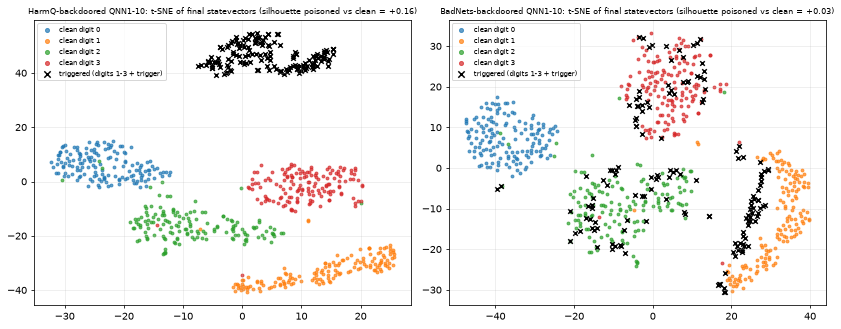

silhouette (poisoned vs clean): {'HarmQ': 0.162, 'BadNets': 0.034}


In [24]:
def final_states(arch, L, w, F16):
    with torch.no_grad(): return evolve(torch.as_tensor(np.asarray(F16, dtype=np.float32)), w, arch, L).numpy()          # complex statevectors (n, 256)

rt = np.random.default_rng(SEED)
pick_clean = np.concatenate([rt.choice(np.flatnonzero(y_te == d), N_TSNE, replace=False) for d in range(4)])
pick_poison = rt.choice(np.flatnonzero(y_te != TARGET), N_TSNE, replace=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8)); SIL = {}
for ax, (name, trig) in zip(axs, (("HarmQ", trig_h), ("BadNets", trig_b))):
    b = RUNS[("QNN1", 10, name, SEED, DOWNSAMPLE, POISON_RATE)]
    Fc = downsample(X28_te[pick_clean], DOWNSAMPLE); Fp = downsample(trig(X28_te[pick_poison]), DOWNSAMPLE)
    S = final_states("QNN1", 10, b["w"], np.vstack([Fc, Fp]))
    fid = np.abs(S @ S.conj().T) ** 2; D = np.sqrt(np.clip(1 - fid, 0, None)); np.fill_diagonal(D, 0)
    emb = TSNE(n_components=2, metric="precomputed", init="random", perplexity=30, random_state=SEED).fit_transform(D)
    is_p = np.r_[np.zeros(len(pick_clean), int), np.ones(len(pick_poison), int)]
    SIL[name] = float(silhouette_score(D, is_p, metric="precomputed"))
    for d in range(4):
        m = np.r_[y_te[pick_clean] == d, np.zeros(len(pick_poison), bool)]
        ax.scatter(emb[m, 0], emb[m, 1], s=9, alpha=0.7, color=DCOL[d], label=f"clean digit {d}")
    ax.scatter(emb[is_p == 1, 0], emb[is_p == 1, 1], s=22, marker="x", color="k", label="triggered (digits 1-3 + trigger)")
    ax.set_title(f"{name}-backdoored QNN1-10: t-SNE of final statevectors (silhouette poisoned vs clean = {SIL[name]:+.2f})", fontsize=8); ax.legend(fontsize=7, markerscale=1.4)
plt.tight_layout(); plt.show(); print("silhouette (poisoned vs clean):", {k: round(v, 3) for k, v in SIL.items()})

In [25]:
def spectral_signature(name, trig):
    b = RUNS[("QNN1", 10, name, SEED, DOWNSAMPLE, POISON_RATE)]
    Xp, yp, pidx = make_poisoned(X28_sub, y_sub, trig, TARGET, POISON_RATE, SEED)
    m = yp == TARGET; is_p = np.isin(np.arange(len(yp)), pidx)[m]
    S = final_states("QNN1", 10, b["w"], downsample(Xp[m], DOWNSAMPLE)); R = np.concatenate([S.real, S.imag], 1); R = R - R.mean(0)
    v = np.linalg.svd(R, full_matrices=False)[2][0]; sc = (R @ v) ** 2
    return dict(attack=name, n_target_label=int(m.sum()), n_poisoned=int(is_p.sum()), AUROC=float(roc_auc_score(is_p, sc)),
                score_ratio=float(sc[is_p].mean() / sc[~is_p].mean()), mean_norm_score_poisoned=float((sc / sc.max())[is_p].mean()))
SS = pd.DataFrame([spectral_signature(n, t) for n, t in ATT]); print(SS.round(3).to_string(index=False))

   attack  n_target_label  n_poisoned  AUROC  score_ratio  mean_norm_score_poisoned
    HarmQ            1540         500  0.960        4.389                     0.526
  BadNets            1540         500  0.763        4.308                     0.353
Watermark            1540         500  0.755        3.181                     0.352
   Q-FGSM            1540         500  0.937        4.110                     0.460
     QUAP            1540         500  0.920        3.691                     0.431


## 8. Experiment D - ablations on QNN1-10: trigger frequency (Table III), down-sampling method (Table IV), grid size (Table V)

Each row trains one new backdoored QNN1-10 (same seed, same poisoning rate); the row that equals the default configuration (f = 1, average pooling, 16 x 16 grid) reuses the Table I model.

In [26]:
t0 = time.time(); T3, T4, T5 = [], [], []
for f in FREQS:                                         # Table III: trigger frequency
    nm, tr = ("HarmQ", trig_h) if f == FREQ else (f"HarmQ_f{f}", harmq_trigger(GRID, f, AMP))
    r = run_model("QNN1", 10, nm, tr, SEED); T3.append({"frequency": f, "ACC": r["acc"], "ASR": r["asr"]})
for m in DOWNS:                                         # Table IV: down-sampling method
    r = run_model("QNN1", 10, "HarmQ", trig_h, SEED, down=m); T4.append({"method": m, "ACC": r["acc"], "ASR": r["asr"]})
for g in GRIDS:                                         # Table V: trigger grid size (g x g cells copied to 28 x 28 blocks)
    nm, tr = ("HarmQ", trig_h) if g == GRID else (f"HarmQ_g{g}", harmq_trigger(g, FREQ, AMP))
    r = run_model("QNN1", 10, nm, tr, SEED); T5.append({"grid": f"{g}x{g}", "g": g, "ACC": r["acc"], "ASR": r["asr"]})
T3, T4, T5 = pd.DataFrame(T3), pd.DataFrame(T4), pd.DataFrame(T5)
print("\nTable III (frequency)\n", T3.round(2).to_string(index=False), "\nTable IV (down-sampling)\n", T4.round(2).to_string(index=False), "\nTable V (grid size)\n", T5.drop(columns="g").round(2).to_string(index=False))
print(f"ablation block: {(time.time() - t0) / 60:.1f} min")

  QNN1-10 HarmQ_f0.5     rate=0.10 seed=42 down=avg      ACC=84.03  ASR=100.00   (16 s)


  QNN1-10 HarmQ_f3.0     rate=0.10 seed=42 down=avg      ACC=92.40  ASR=100.00   (19 s)


  QNN1-10 HarmQ_f5.0     rate=0.10 seed=42 down=avg      ACC=89.17  ASR= 96.79   (19 s)


  QNN1-10 HarmQ          rate=0.10 seed=42 down=max      ACC=88.60  ASR= 96.63   (15 s)


  QNN1-10 HarmQ          rate=0.10 seed=42 down=bilinear ACC=91.32  ASR=100.00   (16 s)


  QNN1-10 HarmQ_g2       rate=0.10 seed=42 down=avg      ACC=89.37  ASR=100.00   (16 s)


  QNN1-10 HarmQ_g4       rate=0.10 seed=42 down=avg      ACC=89.78  ASR=100.00   (20 s)


  QNN1-10 HarmQ_g8       rate=0.10 seed=42 down=avg      ACC=90.16  ASR=100.00   (21 s)



Table III (frequency)
  frequency   ACC    ASR
       0.5 84.03 100.00
       1.0 89.25 100.00
       3.0 92.40 100.00
       5.0 89.17  96.79 
Table IV (down-sampling)
   method   ACC    ASR
     avg 89.25 100.00
     max 88.60  96.63
bilinear 91.32 100.00 
Table V (grid size)
  grid   ACC   ASR
  2x2 89.37 100.0
  4x4 89.78 100.0
  8x8 90.16 100.0
16x16 89.25 100.0
ablation block: 2.4 min


## 9. Experiment E - fine-tuning defence (Table VI)

The defender owns 1,000 clean training images and fine-tunes the backdoored QNN1-10 on them for 5 / 10 / 15 epochs (Adam, fresh optimiser, same learning rate). If the backdoor is only a thin layer on top of the clean function, fine-tuning on clean data should wash it out.

In [27]:
bd = RUNS[("QNN1", 10, "HarmQ", SEED, DOWNSAMPLE, POISON_RATE)]
Fc_, Ft_ = eval_feats("HarmQ", trig_h, DOWNSAMPLE); F_ft = downsample(X28_ft, DOWNSAMPLE)
# CHOICE: the fine-tuning learning rate is not given. Two values are run: the training learning rate LR and the customary smaller LR / 10.
T6all = {}
for lr_ft in (LR, LR / 10):
    res = {0: acc_asr("QNN1", 10, bd["w"], Fc_, y_te, Ft_, TARGET)}
    def _cb(ep, w, res=res):
        if ep in FT_EPOCHS: res[ep] = acc_asr("QNN1", 10, w, Fc_, y_te, Ft_, TARGET)
    train_qnn("QNN1", 10, F_ft, y_ft, SEED + 5, max(FT_EPOCHS), lr=lr_ft, w0=bd["w"], on_epoch=_cb)
    T6all[lr_ft] = pd.DataFrame([{"fine-tuning epochs": e, "ACC": a, "ASR": s} for e, (a, s) in sorted(res.items())])
    print(f"fine-tuning with learning rate {lr_ft}:\n" + T6all[lr_ft].round(2).to_string(index=False))
T6 = T6all[LR / 10]          # the row set compared with the paper (smaller, customary fine-tuning rate); the training-rate run is shown above for transparency

fine-tuning with learning rate 0.03:
 fine-tuning epochs   ACC    ASR
                  0 89.25 100.00
                  5 91.41  94.77
                 10 90.47  69.53
                 15 91.92  41.89


fine-tuning with learning rate 0.003:
 fine-tuning epochs   ACC    ASR
                  0 89.25 100.00
                  5 91.00 100.00
                 10 91.22  99.50
                 15 90.98  98.33


## 10. Side by side with the paper

Verdict rule for a number: **reproduced** when the notebook value is within 2 percentage points of the paper's; otherwise **not reached** (notebook lower) or **exceeded** (notebook higher) with the gap. Claims about trends or orderings are checked as statements. Fashion-MNIST numbers and Fig. 6's absolute outlier scores **cannot be checked** here.
**Budget caveat.** The notebook trains on a subset of the data for fewer epochs than the paper (see the configuration cell), so clean accuracies are expected to fall short of the paper's; the *attack* numbers (ASR) are the robust part.

In [28]:
P1 = {("QNN1", 10): (92.92, 92.37, 99.62), ("QNN1", 20): (96.43, 93.33, 99.46), ("QNN1", 50): (98.67, 97.97, 100.00),
      ("QNN2", 10): (91.87, 90.76, 99.53), ("QNN2", 20): (96.50, 94.99, 98.84), ("QNN2", 50): (98.76, 98.09, 99.97),
      ("QNN3", 10): (94.77, 94.37, 99.18), ("QNN3", 20): (95.27, 94.18, 99.12), ("QNN3", 50): (95.18, 99.31, 99.40)}      # Table I, MNIST: ACC_clean, ACC_bd, ASR_bd
P2 = {"BadNets": (92.63, 2.77), "Watermark": (92.82, 7.96), "Q-FGSM": (92.30, 44.32), "QUAP": (92.20, 3.40), "HarmQ": (92.75, 99.93)}   # Table II (ACC, ASR)
P3 = {0.5: (90.17, 100.00), 1.0: (92.31, 99.94), 3.0: (91.33, 99.46), 5.0: (92.75, 99.84)}                                 # Table III
P4 = {"avg": (92.93, 99.46), "max": (92.74, 99.53), "bilinear": (93.13, 100.00)}                                           # Table IV
P5 = {2: (92.06, 82.03), 4: (93.12, 92.07), 8: (92.39, 99.34), 16: (92.85, 99.69)}                                         # Table V
P6 = {0: (92.78, 99.95), 5: (93.32, 92.92), 10: (93.75, 88.33), 15: (93.97, 84.82)}                                       # Table VI

rows = []
def cmp(claim, paper, nb, tol=2.0):
    if nb is None or (isinstance(nb, float) and np.isnan(nb)): rows.append(dict(claim=claim, paper=paper, notebook=None, gap=None, verdict="cannot be checked in this run")); return
    d = nb - paper; v = "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")
    rows.append(dict(claim=claim, paper=round(paper, 2), notebook=round(nb, 2), gap=round(d, 2), verdict=v))
for _, r in T1.iterrows():
    if (r.arch, r.L) not in P1:                              # FAST_MODE uses QNN3 with 3 layers, which the paper does not report
        rows.append(dict(claim=f"Table I {r.model} (ACC_clean / ACC_bd / ASR_bd)", paper=None, notebook=f"{r.ACC_clean:.1f} / {r.ACC_bd:.1f} / {r.ASR_bd:.1f}", gap=None, verdict="cannot be checked (depth not in the paper)")); continue
    pa, pb, ps = P1[(r.arch, r.L)]
    cmp(f"Table I {r.model} ACC_clean", pa, r.ACC_clean); cmp(f"Table I {r.model} ACC_bd", pb, r.ACC_bd); cmp(f"Table I {r.model} ASR_bd", ps, r.ASR_bd)
for (a_, l_), (pa, pb, ps) in P1.items():
    if not ((T1.arch == a_) & (T1.L == l_)).any(): rows.append(dict(claim=f"Table I {a_}-{l_} (ACC_clean / ACC_bd / ASR_bd)", paper=f"{pa} / {pb} / {ps}", notebook=None, gap=None, verdict="cannot be checked in this run (FAST_MODE)"))
for _, r in T2.iterrows(): cmp(f"Table II {r.attack} ACC", P2[r.attack][0], r.ACC_bd); cmp(f"Table II {r.attack} ASR", P2[r.attack][1], r.ASR_bd)
for _, r in T3.iterrows(): cmp(f"Table III f={r.frequency} ASR", P3[r.frequency][1], r.ASR)
for _, r in T4.iterrows(): cmp(f"Table IV {r.method} ASR", P4[r.method][1], r.ASR)
for _, r in T5.iterrows(): cmp(f"Table V grid {r.grid} ASR", P5[r.g][1], r.ASR)
for _, r in T6.iterrows(): cmp(f"Table VI fine-tune {int(r['fine-tuning epochs'])} ep ASR (lr/10)", P6[int(r['fine-tuning epochs'])][1], r.ASR)
for f in (0.5, 1.0, 3.0, 5.0):
    if f not in set(T3.frequency): cmp(f"Table III f={f} ASR", P3[f][1], None)
for m in P4:
    if m not in set(T4.method): cmp(f"Table IV {m} ASR", P4[m][1], None)
for g in P5:
    if g not in set(T5.g): cmp(f"Table V grid {g}x{g} ASR", P5[g][1], None)
for e in P6:
    if e not in set(T6["fine-tuning epochs"]): cmp(f"Table VI fine-tune {e} ep ASR", P6[e][1], None)
CMP = pd.DataFrame(rows); pd.set_option("display.width", 200)
print(CMP.to_string(index=False)); print("\nverdict counts:\n" + CMP.verdict.value_counts().to_string())

                               claim  paper  notebook    gap     verdict
           Table I QNN1-10 ACC_clean  92.92     92.01  -0.91  reproduced
              Table I QNN1-10 ACC_bd  92.37     89.25  -3.12 not reached
              Table I QNN1-10 ASR_bd  99.62    100.00   0.38  reproduced
           Table I QNN1-20 ACC_clean  96.43     92.49  -3.94 not reached
              Table I QNN1-20 ACC_bd  93.33     91.72  -1.61  reproduced
              Table I QNN1-20 ASR_bd  99.46    100.00   0.54  reproduced
           Table I QNN1-50 ACC_clean  98.67     95.09  -3.58 not reached
              Table I QNN1-50 ACC_bd  97.97     95.04  -2.93 not reached
              Table I QNN1-50 ASR_bd 100.00    100.00   0.00  reproduced
           Table I QNN2-10 ACC_clean  91.87     90.50  -1.37  reproduced
              Table I QNN2-10 ACC_bd  90.76     89.32  -1.44  reproduced
              Table I QNN2-10 ASR_bd  99.53    100.00   0.47  reproduced
           Table I QNN2-20 ACC_clean  96.50     93.

In [29]:
# Qualitative claims of the paper, checked as statements
cl = []
def claim(text, ok, detail): cl.append(dict(claim=text, verdict="reproduced" if ok else "not reached", evidence=detail))
claim("Table I: ASR_bd >= 98 % for every architecture/depth run", T1.ASR_bd.min() >= 98, f"min ASR_bd = {T1.ASR_bd.min():.2f}")
dd = (T1.ACC_clean - T1.ACC_bd).abs()
claim("Table I: backdoored model keeps clean accuracy (|ACC_clean - ACC_bd| typically < 1 point)", float(dd.median()) < 1.0, f"median gap = {dd.median():.2f}, max = {dd.max():.2f}")
claim("Abstract: clean accuracy of the backdoored models stays above 90 %", T1.ACC_bd.min() > 90, f"min ACC_bd = {T1.ACC_bd.min():.2f} (budget-limited training, see caveat)")
_gap = T1["ASR_bd"] - T1["ASR_clean(control)"]; _bad = [m for m, g in zip(T1.model, _gap) if g < 50]
claim("Notebook control (not a paper claim): in every Table I model the backdoor is learned, i.e. ASR_bd exceeds the ASR of the CLEAN model under the same trigger by >= 50 points", len(_bad) == 0, "no excess for: " + (", ".join(_bad) if _bad else "none") + (" (the clean model already sends triggered inputs to class 0, so a high ASR there is not evidence of a backdoor)" if _bad else ""))
claim("Table II: HarmQ has the highest ASR of the five attacks",T2.set_index("attack").ASR_bd.idxmax() == "HarmQ", "ASR: " + ", ".join(f"{a} {s:.1f}" for a, s in zip(T2.attack, T2.ASR_bd)))
claim("Table II: BadNets and Watermark reach almost no ASR (< 10 %)", bool((T2.set_index("attack").ASR_bd[["BadNets", "Watermark"]] < 10).all()), "BadNets %.1f, Watermark %.1f" % tuple(T2.set_index("attack").ASR_bd[["BadNets", "Watermark"]]))
claim("Table V: ASR does not decrease as the trigger grid gets finer", bool((np.diff(T5.sort_values("g").ASR.values) >= -2.0).all()), "ASR by grid: " + ", ".join(f"{g} {s:.1f}" for g, s in zip(T5.grid, T5.ASR)))
_t5 = T5.sort_values("g"); claim("Table V: coarse grids are clearly weaker (paper: ASR 82 % at 2x2 versus 99.7 % at 16x16; here the finest grid beats the coarsest by > 5 points)", len(_t5) > 1 and _t5.ASR.iloc[-1] - _t5.ASR.iloc[0] > 5, "ASR by grid: " + ", ".join(f"{g} {s:.1f}" for g, s in zip(_t5.grid, _t5.ASR)))
claim("Table VI:fine-tuning lowers the ASR only gradually (still > 80 % at the last epoch count)", T6.ASR.iloc[-1] > 80 and T6.ASR.iloc[-1] <= T6.ASR.iloc[0] + 1, f"ASR by epochs: " + ", ".join(f"{int(e)}: {s:.1f}" for e, s in zip(T6['fine-tuning epochs'], T6.ASR)))
claim("Fig. 5: HarmQ-triggered inputs separate from the clean classes more than BadNets-triggered inputs", SIL["HarmQ"] > SIL["BadNets"], f"silhouette HarmQ {SIL['HarmQ']:+.2f} vs BadNets {SIL['BadNets']:+.2f}")
claim("Fig. 6: HarmQ evades the spectral signature best (lowest detection AUROC of the five attacks)", SS.set_index("attack").AUROC.idxmin() == "HarmQ", "AUROC: " + ", ".join(f"{a} {s:.2f}" for a, s in zip(SS.attack, SS.AUROC)))
cl = pd.DataFrame(cl)
cl.loc[len(cl)] = dict(claim="Fashion-MNIST rows of Tables I-V; absolute outlier scores of Fig. 6; hardware / Braket", verdict="cannot be checked", evidence="not part of this notebook (MNIST only; OS undefined; paper is a simulation study)")
print(cl.to_string(index=False))
# Notebook-only control (not a paper claim): is the backdoor really learned, or does the trigger already fool a clean model?
print(f"\nControl: ASR of the CLEAN models under the HarmQ trigger: min {T1['ASR_clean(control)'].min():.1f} %, median {T1['ASR_clean(control)'].median():.1f} %, max {T1['ASR_clean(control)'].max():.1f} % (chance level would be about 25 %)")
print(f"Total notebook run time: {(time.time() - T0_NOTEBOOK) / 60:.1f} min")

                                                                                                                                                                      claim           verdict                                                                                                                                                evidence
                                                                                                                   Table I: ASR_bd >= 98 % for every architecture/depth run        reproduced                                                                                                                                     min ASR_bd = 100.00
                                                                                  Table I: backdoored model keeps clean accuracy (|ACC_clean - ACC_bd| typically < 1 point)       not reached                                                                                                                           medi

## 11. Reading the paper critically

The numbers quoted below are those of the executed `FAST_MODE = False` run saved in this notebook (single seed unless stated; QNN1-10 clean accuracy varies by about +-3 points over seeds 42-44, so differences of 2-3 points between rows are within seed noise).

**What reproduces.**
* *The headline attack works.* With 10 % of the training images triggered, every one of the nine backdoored QNNs answers digit 0 for essentially every triggered non-zero test image (ASR 100 %, paper 98.8-100 %), and for QNN1 and QNN2 the clean model does not (control ASR 1-18 %), so the backdoor really is learned. Clean accuracy of the backdoored model is within about 3 points of the clean model's (paper: about 1).
* *The trigger survives shrinking.* The "energy kept" table in section 2 confirms the design argument: a block-uniform sine wave keeps 99 % of its energy under average pooling and bilinear shrinking, the BadNets and Watermark patterns 84-93 %. (Under max pooling every pattern keeps at least 100 %, because the maximum favours added brightness; the shrinking argument is therefore strongest for average and bilinear.)
* *Spread in the quantum state.* Fig. 5: triggered inputs of the HarmQ-backdoored QNN form a more separated group in state space than BadNets-triggered inputs (silhouette +0.16 versus +0.03).
* *Robustness to the trigger's parameters* (Tables III, IV): ASR stays at 97-100 % for frequencies 0.5-5 and for the three shrinking methods.

**What does not reproduce here, and why that matters.**
1. *The baselines are far stronger here than in the paper.* The paper's table shows BadNets at 2.77 % and QUAP at 3.40 %. Here BadNets reaches 20 % (65 % with a larger triangle) and Watermark 18 % (45 % with a stronger blend). The Q-FGSM and QUAP perturbations reach 100 % ASR, but their **clean-model control is 80 % and 100 %**: with an L-infinity budget of 0.5 on [0, 1] images (the same budget as HarmQ) they are simply universal adversarial perturbations that fool even a model that was never backdoored. With a budget of 0.1 they fall to 24 % and 43 %. The paper does not give trigger sizes, strengths or budgets, so its low baseline numbers cannot be rebuilt; what the sensitivity table shows is that the baseline ASR is a function of those unstated choices. "HarmQ beats the baselines" therefore holds in this notebook only in a weak form (HarmQ reaches 100 % at a trigger with a 3.6 % control, BadNets and Watermark do not), not as a margin of 90 points.
2. *The paper's weaker-grid effect is absent.* The paper reports ASR 82 % and 92 % for 2 x 2 and 4 x 4 grids; here every grid gives 100 %. A 2 x 2 sine pattern is still a large, high-contrast, image-wide signal that a 240-parameter circuit separates easily.
3. *Fine-tuning defence.* The paper's ASR falls slowly (99.95 -> 84.8 % after 15 epochs). The result depends strongly on the fine-tuning learning rate, which the paper does not state: at lr 0.003 the ASR stays at 98 %, at the training rate 0.03 it falls to 42 %. The paper's figures lie between the two.
4. *Spectral signature.* The paper claims HarmQ is the hardest attack to detect. Here the spectral-signature score separates HarmQ-poisoned samples with AUROC 0.96, *better* than for BadNets (0.76) or Watermark (0.76): a 10 %-strong, image-wide trigger is a large, coherent direction in the target-class representations. The paper's absolute "outlier score" is undefined, so this comparison is a different (and, in our view, more standard) measurement.
5. *QNN3 is not a valid test here.* Our Farhi-Neven implementation (a CHOICE: RZX/RXX chain, Pauli-Y readout of qubits 0-3) trains badly (about 75 % accuracy against the paper's 95 %), and the **clean** QNN3 already classifies 95-100 % of triggered images as digit 0. The trigger shifts the amplitude vector in a direction this poorly trained circuit maps to class 0, so QNN3's 100 % ASR is not evidence of a backdoor. The paper's 98.8-100 % for QNN3 can neither be confirmed nor refuted.
6. *Accuracy.* The notebook trains on 5,000 images for 6 epochs; the paper uses all 24.7k images for 10 epochs. Clean accuracies are 3-4 points lower for the deeper models (95 % against 98.7 % at 50 layers).

**Questions the paper leaves open (and the exercises probe).** The poisoning rate is not stated; the task is a four-class MNIST subset (0-3) with a very strong, dataset-wide additive trigger of norm 9.9 on the 28 x 28 image (BadNets: 3.2); such a trigger is also trivial for *classical* models: the random forest and the RBF-SVM of section 4 are 100 % backdoored by every one of the three triggers (HarmQ, BadNets, Watermark) at the same 10 % rate, with no loss of clean accuracy, so the weakness is a property of the data poisoning setting, not specific to quantum circuits, and the paper's claim that classical triggers fail "because of the quantum constraints" is only tested against the baselines the authors chose. Finally, everything here is an exact noise-free statevector simulation; noise, shot sampling and real devices (the paper names Amazon Braket only as a cloud example) are not tested, so nothing in this notebook says whether the backdoor survives on hardware.

## 12. Exercises

1. **Poisoning rate.** Re-run QNN1-10 with `POISON_RATE` in {0.005, 0.01, 0.02, 0.05}. What is the smallest rate at which HarmQ still reaches 90 % ASR, and what is the ASR of BadNets at the same rates? (The paper never states its rate.)
2. **Amplitude of the trigger.** Change `AMP` to 0.1, 0.2 and 0.3. At which intensity does the *clean-model control* ASR start to rise, and at which does the backdoored model lose its ASR? Plot ACC and ASR against `AMP`.
3. **Fair baselines.** Make BadNets and Watermark as strong as the paper's notion of "classical trigger" (try legs = 8, 10 and blending weights 0.3-0.5) and compare their ACC / ASR with HarmQ's at *equal L2 norm of the added perturbation* (`norm_28x28` in section 2). Does HarmQ still win?
4. **QNN3.** Improve our QNN3 (more epochs, a different readout, data re-uploading) until its clean accuracy approaches the paper's 95 %. Does the clean-model control ASR fall to a few percent, and does the backdoored ASR stay at 100 %?
5. **Defence.** Using only the defender's 1,000 clean images, add a simple detector: compute the spectral-signature AUROC of section 7 for a *clean* training set (no poisoning) to calibrate the score, then flag the top 5 % of target-label samples and retrain without them. How much ASR remains for HarmQ and for BadNets?
6. **Noise (hard).** Execute the trained QNN1-10 circuits with `default.mixed` and a depolarising channel after each layer (p = 0.001, 0.005, 0.01). Does the ASR of the HarmQ backdoor survive?